# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 2: Advanced Data Preprocessing, Feature Engineering & Model Development

| | |
|---|---|
| **Student name** | Dinh Phu Nguyen |
| **Student ID** | 105027282 |
| **Date** | 18 Oct 2026 |
| **Dataset** | Appliances Energy Prediction – Candanedo, L. (2017), UCI Machine Learning Repository, DOI: [10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G) |

## Generative AI Use Declaration

"I used Claude (Anthropic) to assist with, analyzing rubric requirements. All final code, interpretations, and conclusions are my own work after verification."

*Evidence of the GenAI use is provided in the appendix of the PDF report.*

## Contents
0. Setup and data (cleaned as in Portfolio 1)
1. Task 1 – Target Variable Preparation
2. Task 2 – Feature Normalisation & Transformation
3. Task 3 – Feature Engineering
4. Task 4 – Decision Tree Modelling on Five Feature Sets
5. Task 5 – Results Comparison Table (Decision Trees)
6. Task 6 – Model Improvement with SVM (70/30 split and 5-fold CV)
7. Task 7 – Hyperparameter Tuning (GridSearchCV)
8. Task 8 – Feature Selection (SelectKBest)
9. Task 9 – Dimensionality Reduction (PCA)
10. Task 10 – Final Results Table

References to Portfolio 1 are written as **PA1 §x.y** (section numbers of the Portfolio 1 notebook).

## 0. Setup and data
Imports, global settings and helpers. All random operations use `RANDOM_STATE` so the results are reproducible.

In [1]:
# --- Imports ---
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from matplotlib.patches import Patch

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# --- Reproducibility & evaluation settings ---
RANDOM_STATE = 42
TEST_SIZE = 0.30          # 70/30 train-test split (Studio 3)
N_FOLDS = 5               # 5-fold cross-validation (brief, Task 6)
N_JOBS = -1               # use all CPU cores for cross-validation and grid search

DATA_PATH = Path("data") / "energydata_complete.csv"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# --- Display & plotting defaults ---
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

COLOR_MAIN = "#2a78d6"     # blue
COLOR_SECOND = "#eb6834"   # orange
COLOR_THIRD = "#1baf7a"    # aqua
COLOR_GREY = "#b5b4ad"     # de-emphasised bars
COLOR_TEXT = "#52514e"     # annotations
CLASS_PALETTE = {"Low": COLOR_MAIN, "Medium": COLOR_SECOND, "High": COLOR_THIRD}


def save_fig(fig, name):
    """Save a figure to figures/<name>.png at print resolution."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    return path


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


### 0.1 Load and clean the data (same cleaning as PA1 §2.5)
- `date` converted from text to datetime.
- `rv1` and `rv2` removed (random noise columns, identical to each other – PA1 §2.3).
- `RH_6` removed (outdoor wall sensor with drift and readings stuck at 1% / 99.9% – PA1 §2.4.4).
- No rows removed; outliers kept because they are physically valid (PA1 §2.4).

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d %H:%M:%S")
df = df.drop(columns=["rv1", "rv2", "RH_6"]).sort_values("date").reset_index(drop=True)

TARGET = "Appliances"
ORIGINAL_FEATURES = [c for c in df.columns if c not in ("date", TARGET)]   # 24 sensor/weather predictors

UNITS = {"Appliances": "Wh", "lights": "Wh", "T_out": "°C", "Tdewpoint": "°C", "RH_out": "%",
         "Press_mm_hg": "mm Hg", "Windspeed": "m/s", "Visibility": "km"}
UNITS.update({c: "°C" for c in ORIGINAL_FEATURES if c.startswith("T") and c[1:].isdigit()})
UNITS.update({c: "%" for c in ORIGINAL_FEATURES if c.startswith("RH_") and c[3:].isdigit()})

print(f"Cleaned data: {df.shape[0]:,} rows x {df.shape[1]} columns | {len(ORIGINAL_FEATURES)} original predictors")
print(f"Time span: {df['date'].min()} to {df['date'].max()} | missing values: {int(df.isna().sum().sum())}")

Cleaned data: 19,735 rows x 26 columns | 24 original predictors
Time span: 2016-01-11 17:00:00 to 2016-05-27 18:00:00 | missing values: 0


## 1. Task 1 – Target Variable Preparation
`Appliances` (Wh per 10 minutes) is numeric, so it is discretised into classes (brief option 1.1). The class definition is taken from the EDA in Portfolio 1:

- The target is strongly right-skewed (skewness 3.39, mean 97.7 Wh vs median 60 Wh) and recorded in 10 Wh steps, with 22% of readings exactly 50 Wh (PA1 §3.2).
- Equal-width binning put 96.2% of readings into one class; equal-frequency binning with 3 classes gave the best balance (balance ratio 0.81 vs 0.44 for 4 classes and 0.21 for 5 classes) (PA1 §3.3).
- The two boundaries (50 and 80 Wh) also have a physical meaning: the night-time base load has a median of exactly 50 Wh, and the 17:00–20:00 cooking peak lies above 80 Wh (PA1 §3.3, hourly profile).

,count,min_Wh,max_Wh,median_Wh,pct,avg_power_W
Appliances_class,,,,,,
Low,7462,10,50,50.0,37.8,60–300
Medium,6047,60,80,60.0,30.6,360–480
High,6226,90,1080,120.0,31.5,"540–6,480"


Balance ratio (smallest / largest class): 0.81 – no class is above the 80% imbalance level


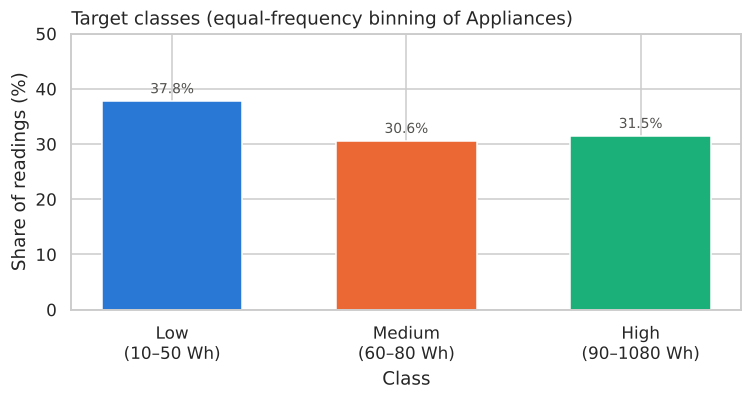

In [3]:
CLASS_EDGES = [-np.inf, 50, 80, np.inf]        # Wh per 10 minutes (equal-frequency quantiles from PA1 §3.3)
CLASS_LABELS = ["Low", "Medium", "High"]
CLASS_COL = "Appliances_class"

df[CLASS_COL] = pd.cut(df[TARGET], bins=CLASS_EDGES, labels=CLASS_LABELS, ordered=True)

class_table = df.groupby(CLASS_COL, observed=False)[TARGET].agg(count="size", min_Wh="min", max_Wh="max", median_Wh="median")
class_table["pct"] = (class_table["count"] / len(df) * 100).round(1)
class_table["avg_power_W"] = [f"{lo * 6}–{hi * 6:,}" for lo, hi in zip(class_table["min_Wh"], class_table["max_Wh"])]
display(class_table)
balance_ratio = class_table["count"].min() / class_table["count"].max()
print(f"Balance ratio (smallest / largest class): {balance_ratio:.2f} – no class is above the 80% imbalance level")

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar([f"{c}\n({lo}–{hi} Wh)" for c, lo, hi in zip(class_table.index, class_table["min_Wh"], class_table["max_Wh"])],
              class_table["pct"], color=[CLASS_PALETTE[c] for c in class_table.index], width=0.6)
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in class_table["pct"]], padding=3, color=COLOR_TEXT, fontsize=9)
ax.set_ylim(0, 50)
ax.set_title("Target classes (equal-frequency binning of Appliances)", loc="left")
ax.set_xlabel("Class")
ax.set_ylabel("Share of readings (%)")
fig.tight_layout()
save_fig(fig, "pa2_task1_class_distribution")
plt.show()

### 1.1 Task 1 observations
- **Classes:** Low ≤ 50 Wh (37.8% of readings), Medium 60–80 Wh (30.6%) and High ≥ 90 Wh (31.5%). The balance ratio is 0.81 and no class comes close to the 80% imbalance level, so accuracy is a meaningful metric. The majority-class baseline is 37.8%, and macro-F1 is reported as well.
- **Link to the EDA:** equal-width bins would have put 96.2% of readings into one class, and 4 or 5 equal-frequency classes were unbalanced because the very common values 50 and 60 Wh cannot be split (PA1 §3.3). The 10 Wh meter steps are also why the three classes cannot be exactly equal (PA1 §3.2).
- **Physical meaning:** Low corresponds to the night-time base load (≈300 W), Medium to light daytime activity, and High to the use of high-power appliances such as cooking in the evening peak (PA1 §3.3).
- **Expected difficulty:** Medium covers the narrowest range (60–80 Wh) and lies between the other two classes, so it is likely to be the hardest class to predict. The labels are ordinal (Low = 0 < Medium = 1 < High = 2).

## 2. Task 2 – Feature Normalisation & Transformation
### 2.1 Scaling plan for each numerical feature
Each continuous feature gets a scaler chosen from its distribution in the EDA (PA1 §4.3: skewness, share of zeros; PA1 §2.4.2: IQR outlier share). Two plans are documented:

| Rule (checked in this order) | Brief's recommended scaler | Final choice used in the models |
|---|---|---|
| Binary 0/1 or cyclic sin/cos feature | – (already on a 0–1 or −1…1 scale) | passthrough |
| Zero-inflated (> 50% zeros) | MinMaxScaler | Yeo-Johnson power transform + standardise |
| IQR outliers > 5% | RobustScaler | Yeo-Johnson power transform + standardise |
| Skewed (\|skew\| ≥ 0.5) | MinMaxScaler | Yeo-Johnson power transform + standardise |
| Approximately symmetric | StandardScaler | StandardScaler |

The brief's mapping is tested first; section 2.3 shows why the final choice refines it for distance-based models such as SVM. All scalers are **fitted on the training data only** (inside scikit-learn pipelines), so no information from the test set leaks into the preprocessing.

In [4]:
def feature_profile(series):
    """Distribution statistics used to choose a scaler (same definitions as PA1)."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_pct = ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).mean() * 100 if iqr > 0 else np.nan
    return {"skew": series.skew(), "outlier_pct": outlier_pct, "zero_pct": (series == 0).mean() * 100,
            "n_unique": series.nunique()}


def scaling_group(name, prof):
    """Return (rule, brief scaler, final scaler) for one feature."""
    if prof["n_unique"] <= 2 or name in ("hour_sin", "hour_cos"):
        return "binary / cyclic", "passthrough", "passthrough"
    if prof["zero_pct"] > 50:
        return "zero-inflated", "MinMaxScaler", "PowerTransformer"
    if prof["outlier_pct"] > 5:
        return "outliers > 5%", "RobustScaler", "PowerTransformer"
    if abs(prof["skew"]) >= 0.5:
        return "skewed", "MinMaxScaler", "PowerTransformer"
    return "approx. symmetric", "StandardScaler", "StandardScaler"


def scaling_table(frame, columns):
    rows = []
    for c in columns:
        prof = feature_profile(frame[c])
        rule, brief, final = scaling_group(c, prof)
        rows.append({"feature": c, "skew": round(prof["skew"], 2),
                     "IQR_outlier_pct": None if pd.isna(prof["outlier_pct"]) else round(prof["outlier_pct"], 2),
                     "zero_pct": round(prof["zero_pct"], 1), "rule": rule,
                     "brief_scaler": brief, "final_scaler": final})
    return pd.DataFrame(rows).set_index("feature")


scaling_plan = scaling_table(df, ORIGINAL_FEATURES)
display(scaling_plan)
print(scaling_plan["final_scaler"].value_counts().to_string())

,skew,IQR_outlier_pct,zero_pct,rule,brief_scaler,final_scaler
feature,,,,,,
lights,2.20,NaN,77.3,zero-inflated,MinMaxScaler,PowerTransformer
T1,0.12,2.61,0.0,approx. symmetric,StandardScaler,StandardScaler
RH_1,0.47,0.74,0.0,approx. symmetric,StandardScaler,StandardScaler
T2,0.89,2.77,0.0,skewed,MinMaxScaler,PowerTransformer
RH_2,-0.27,1.19,0.0,approx. symmetric,StandardScaler,StandardScaler
T3,0.45,1.10,0.0,approx. symmetric,StandardScaler,StandardScaler
RH_3,0.47,0.08,0.0,approx. symmetric,StandardScaler,StandardScaler
T4,0.17,0.94,0.0,approx. symmetric,StandardScaler,StandardScaler
RH_4,0.44,0.00,0.0,approx. symmetric,StandardScaler,StandardScaler


final_scaler
StandardScaler      15
PowerTransformer     9


In [5]:
SCALERS = {"StandardScaler": StandardScaler, "MinMaxScaler": MinMaxScaler, "RobustScaler": RobustScaler,
           "PowerTransformer": lambda: PowerTransformer(method="yeo-johnson", standardize=True)}


def make_preprocessor(columns, plan, which="final_scaler"):
    """ColumnTransformer that applies the planned scaler to each column (columns not in the plan pass through)."""
    groups = {}
    for c in columns:
        scaler = plan.loc[c, which] if c in plan.index else "passthrough"
        groups.setdefault(scaler, []).append(c)
    transformers = [(name, "passthrough" if name == "passthrough" else SCALERS[name](), cols)
                    for name, cols in groups.items()]
    return ColumnTransformer(transformers, verbose_feature_names_out=False)


# Stratified 70/30 split for the preprocessing analysis in Task 2
# (the modelling split is created in Task 4 from the shuffled modelling file)
prep_train_idx, prep_test_idx = train_test_split(np.arange(len(df)), test_size=TEST_SIZE,
                                                 stratify=df[CLASS_COL], random_state=RANDOM_STATE)
print(f"Training rows: {len(prep_train_idx):,} | test rows: {len(prep_test_idx):,}")

# Before/after statistics of every original feature (scalers fitted on the training rows)
pre_orig = make_preprocessor(ORIGINAL_FEATURES, scaling_plan).set_output(transform="pandas")
X_before = df.loc[prep_train_idx, ORIGINAL_FEATURES]
X_after = pre_orig.fit_transform(X_before)[ORIGINAL_FEATURES]
before_after = pd.concat({"before": X_before.describe().T[["mean", "std", "min", "max"]],
                          "after": X_after.describe().T[["mean", "std", "min", "max"]]}, axis=1)
before_after.insert(0, "scaler", scaling_plan["final_scaler"])
display(before_after.round(2))

Training rows: 13,814 | test rows: 5,921


scaler  before                        after                 
                                 mean    std     min     max  mean  std   min   max
lights       PowerTransformer    3.84   7.94    0.00   70.00  -0.0  1.0 -0.55  1.87
T1             StandardScaler   21.69   1.60   16.79   26.26   0.0  1.0 -3.07  2.86
RH_1           StandardScaler   40.29   3.98   27.23   63.36   0.0  1.0 -3.28  5.80
T2           PowerTransformer   20.34   2.18   16.10   29.67  -0.0  1.0 -2.73  2.78
RH_2           StandardScaler   40.44   4.06   20.46   56.03  -0.0  1.0 -4.91  3.83
T3             StandardScaler   22.27   2.00   17.20   29.20   0.0  1.0 -2.53  3.46
RH_3           StandardScaler   39.25   3.25   28.77   50.16  -0.0  1.0 -3.22  3.35
T4             StandardScaler   20.86   2.03   15.10   26.20  -0.0  1.0 -2.83  2.62
RH_4           StandardScaler   39.04   4.34   27.66   51.09   0.0  1.0 -2.62  2.78
T5           PowerTransformer   19.59   1.84   15.34   25.80  -0.0  1.0 -2.98  2.66
RH_5         PowerTransformer   50.95   9.01   29.82   95.39  -0.0  1.0 -6.20  2.64
T6           PowerTransformer    7.90   6.07   -6.06   28.24   0.0  1.0 -3.03  2.98
T7             StandardScaler   20.27   2.11   15.39   26.00  -0.0  1.0 -2.32  2.72
RH_7           StandardScaler   35.40   5.11   23.20   51.40  -0.0  1.0 -2.39  3.13
T8             StandardScaler   22.03   1.95   16.31   27.23   0.0  1.0 -2.94  2.67
RH_8           StandardScaler   42.96   5.21   29.60   58.78  -0.0  1.0 -2.56  3.03
T9             StandardScaler   19.49   2.01   14.89   24.50   0.0  1.0 -2.28  2.49
RH_9           StandardScaler   41.56   4.14   29.17   53.09   0.0  1.0 -2.99  2.79
T_out        PowerTransformer    7.41   5.31   -5.00   26.10  -0.0  1.0 -3.04  3.12
Press_mm_hg    StandardScaler  755.47   7.46  729.30  772.30   0.0  1.0 -3.51  2.26
RH_out       PowerTransformer   79.81  14.84   24.00  100.00  -0.0  1.0 -2.18  1.76
Windspeed    PowerTransformer    4.04   2.46    0.00   14.00   0.0  1.0 -2.96  2.52
Visibility   PowerTransformer   38.34  11.77    1.00   66.00   0.0  1.0 -4.26  2.18
Tdewpoint      StandardScaler    3.78   4.19   -6.60   15.50   0.0  1.0 -2.48  2.80

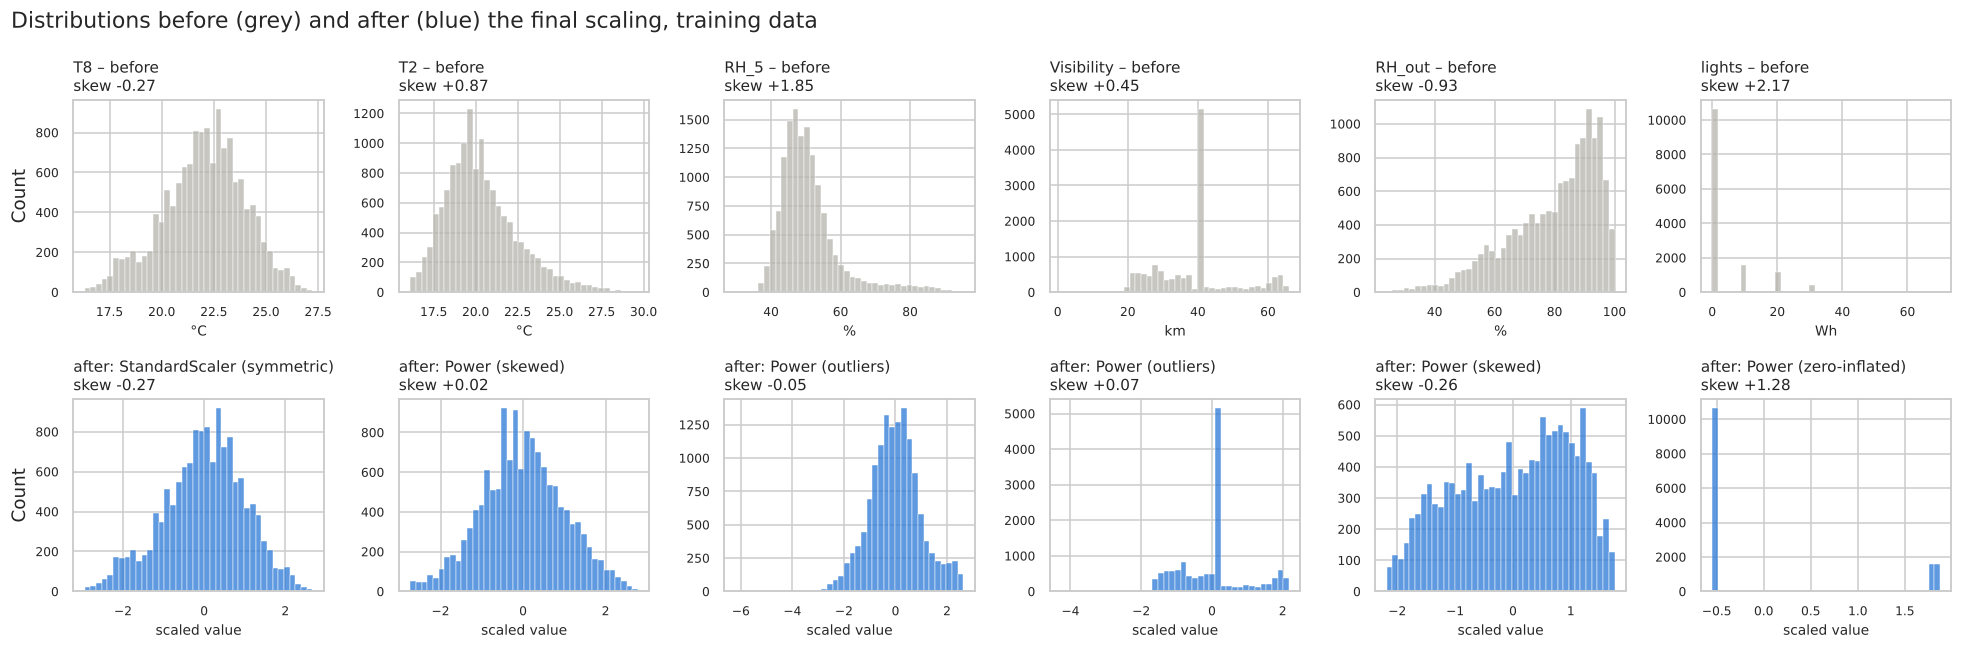

In [6]:
# Visual before/after comparison for one feature of each type
SHOWCASE = {"T8": "StandardScaler (symmetric)", "T2": "Power (skewed)", "RH_5": "Power (outliers)",
            "Visibility": "Power (outliers)", "RH_out": "Power (skewed)", "lights": "Power (zero-inflated)"}
fig, axes = plt.subplots(2, len(SHOWCASE), figsize=(18, 6))
for i, (col, label) in enumerate(SHOWCASE.items()):
    sns.histplot(X_before[col], bins=40, ax=axes[0, i], color=COLOR_GREY, edgecolor="white", linewidth=0.3)
    sns.histplot(X_after[col], bins=40, ax=axes[1, i], color=COLOR_MAIN, edgecolor="white", linewidth=0.3)
    axes[0, i].set_title(f"{col} – before\nskew {X_before[col].skew():+.2f}", loc="left", fontsize=10)
    axes[1, i].set_title(f"after: {label}\nskew {X_after[col].skew():+.2f}", loc="left", fontsize=10)
    axes[0, i].set_xlabel(UNITS.get(col, ""), fontsize=9)
    axes[1, i].set_xlabel("scaled value", fontsize=9)
    for r in (0, 1):
        axes[r, i].set_ylabel("Count" if i == 0 else "")
        axes[r, i].tick_params(labelsize=8)
fig.suptitle("Distributions before (grey) and after (blue) the final scaling, training data", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "pa2_task2_before_after")
plt.show()

### 2.2 Encoding non-numerical information
All 24 original predictors are already numeric. The non-numerical information is the **timestamp** (`date`) and the **class label**:

| Source | New feature(s) | Type | Encoding | Why |
|---|---|---|---|---|
| `date` → hour of day | `hour_sin`, `hour_cos` | cyclic | sine/cosine | 23:00 and 00:00 are neighbours; an ordinal 0–23 code would place them far apart. Hour of day is the strongest driver of the target (η = 0.387, PA1 §5.2.1). |
| `date` → period of day | `period_night`, `period_morning`, `period_afternoon`, `period_evening`, `period_late_evening` | nominal, 5 categories | one-hot | Household routine phases from the hourly profile (PA1 §3.3); fewer than 10 categories, no numeric order. |
| `date` → day of week | `is_weekend` | binary | 0/1 | Weekday vs weekend routine (PA1 §5.2.1, η = 0.086). |
| `Appliances_class` | `y` = 0, 1, 2 | ordinal | ordinal encoding | Low < Medium < High has a natural order. |

In [7]:
hour_decimal = df["date"].dt.hour + df["date"].dt.minute / 60
df["hour_sin"] = np.sin(2 * np.pi * hour_decimal / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour_decimal / 24)
df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)

PERIODS = ["night", "morning", "afternoon", "evening", "late_evening"]
period = pd.cut(df["date"].dt.hour, bins=[-1, 5, 11, 16, 21, 23], labels=PERIODS)   # 0-5, 6-11, 12-16, 17-21, 22-23
period_onehot = pd.get_dummies(period, prefix="period").astype(int)
df = pd.concat([df, period_onehot], axis=1)

# Ordinal encoding of the target: Low = 0, Medium = 1, High = 2
y = df[CLASS_COL].cat.codes.astype(int)

ENCODED_TIME = ["hour_sin", "hour_cos", "is_weekend"] + list(period_onehot.columns)
display(df[["date"] + ENCODED_TIME].iloc[[0, 40, 90, 120]])
print("Target encoding:", dict(zip(CLASS_LABELS, range(len(CLASS_LABELS)))))

,date,hour_sin,hour_cos,is_weekend,period_night,period_morning,period_afternoon,period_evening,period_late_evening
0,2016-01-11 17:00:00,-0.965926,-0.258819,0,0,0,0,1,0
40,2016-01-11 23:40:00,-0.087156,0.996195,0,0,0,0,0,1
90,2016-01-12 08:00:00,0.866025,-0.500000,0,0,1,0,0,0
120,2016-01-12 13:00:00,-0.258819,-0.965926,0,0,0,1,0,0


Target encoding: {'Low': 0, 'Medium': 1, 'High': 2}


### 2.3 Impact of scaling on model performance
Decision Trees split one feature at a time, so they are not affected by scaling. SVM with an RBF kernel compares observations by **Euclidean distance**, so a feature with a larger spread has more influence. Four scaling strategies are compared on the same 70/30 split (original features + encoded time features, default SVM).

In [8]:
BASE_COLS = ORIGINAL_FEATURES + ENCODED_TIME
plan_base = scaling_table(df, BASE_COLS)
X_base = df[BASE_COLS]

strategies = {
    "No scaling": None,
    "Brief mapping (Standard / MinMax / Robust)": make_preprocessor(BASE_COLS, plan_base, "brief_scaler"),
    "StandardScaler for all features": ColumnTransformer([("std", StandardScaler(), BASE_COLS)]),
    "Final per-feature (Standard / Yeo-Johnson / passthrough)": make_preprocessor(BASE_COLS, plan_base, "final_scaler"),
}
scaling_results = []
for name, pre in strategies.items():
    steps = ([("pre", pre)] if pre is not None else []) + [("svc", SVC())]
    model = Pipeline(steps).fit(X_base.iloc[prep_train_idx], y.iloc[prep_train_idx])
    acc = accuracy_score(y.iloc[prep_test_idx], model.predict(X_base.iloc[prep_test_idx]))
    scaling_results.append({"strategy": name, "SVM test accuracy": acc})
dt_raw = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_base.iloc[prep_train_idx], y.iloc[prep_train_idx])
dt_scaled = Pipeline([("pre", strategies["Final per-feature (Standard / Yeo-Johnson / passthrough)"]),
                      ("dt", DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(X_base.iloc[prep_train_idx], y.iloc[prep_train_idx])
scaling_results = pd.DataFrame(scaling_results).set_index("strategy")
display(scaling_results.round(4))
print(f"Decision Tree accuracy – unscaled: {dt_raw.score(X_base.iloc[prep_test_idx], y.iloc[prep_test_idx]):.4f} | "
      f"scaled: {dt_scaled.score(X_base.iloc[prep_test_idx], y.iloc[prep_test_idx]):.4f}")

# Why the brief mapping underperforms: spread of the features after each scaler (training data)
brief_scaled = strategies["Brief mapping (Standard / MinMax / Robust)"].set_output(transform="pandas").fit_transform(X_base.iloc[prep_train_idx])
spread = pd.DataFrame({"scaler": plan_base.loc[brief_scaled.columns, "brief_scaler"],
                       "std_after": brief_scaled.std(), "max_abs_after": brief_scaled.abs().max()})
display(spread.groupby("scaler")[["std_after", "max_abs_after"]].agg(["mean", "max"]).round(2))

,SVM test accuracy
strategy,
No scaling,0.5092
Brief mapping (Standard / MinMax / Robust),0.6881
StandardScaler for all features,0.7012
Final per-feature (Standard / Yeo-Johnson / passthrough),0.6982


Decision Tree accuracy – unscaled: 0.6970 | scaled: 0.7004


std_after       max_abs_after      
                    mean   max          mean   max
scaler                                            
MinMaxScaler        0.17  0.20          1.00  1.00
RobustScaler        1.07  1.08          4.54  5.54
StandardScaler      1.00  1.00          3.32  5.80
passthrough         0.48  0.71          1.00  1.00

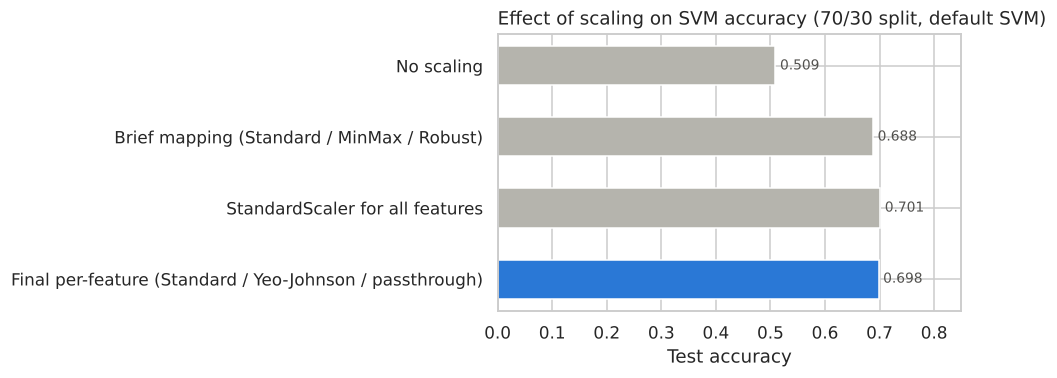

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
vals = scaling_results["SVM test accuracy"]
colors = [COLOR_GREY, COLOR_GREY, COLOR_GREY, COLOR_MAIN]
bars = ax.barh(vals.index[::-1], vals.values[::-1], color=colors[::-1], height=0.55)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in vals.values[::-1]], padding=3, color=COLOR_TEXT, fontsize=9)
ax.set_xlim(0, 0.85)
ax.set_title("Effect of scaling on SVM accuracy (70/30 split, default SVM)", loc="left")
ax.set_xlabel("Test accuracy")
fig.tight_layout()
save_fig(fig, "pa2_task2_scaling_impact")
plt.show()

### 2.4 Task 2 observations
- **Which features were scaled:** all continuous features. Fifteen original features that are approximately symmetric with few outliers (most indoor temperatures and humidities, `Press_mm_hg`, `Tdewpoint`) use **StandardScaler**. The other nine are skewed (`T2`, `T5`, `T6`, `T_out`, `RH_out`, `Windspeed`), have more than 5% outliers (`RH_5`, `Visibility`) or are zero-inflated (`lights`); they use a **Yeo-Johnson power transform** with standardisation. The brief's table would give these nine features MinMaxScaler (7) or RobustScaler (2).
- **Before/after:** every scaled feature now has mean 0 and standard deviation 1 on the training data, and the power transform removes most of the skew (`T2`: +0.87 → +0.02; `RH_5`: +1.85 → −0.05). Two limits are visible in the histograms. A spike at a single value cannot be spread out by any monotonic transform: `Visibility` still has 37% of readings at one value. A zero-inflated variable stays two-valued: `lights` remains mostly zero, and this is why the binary `lights_on` and the smoother `lights_30min` are added in Task 3.
- **Which features were encoded:** the timestamp, as `hour_sin`/`hour_cos` (cyclic), five one-hot `period_*` columns (nominal, 5 categories) and `is_weekend` (binary 0/1); and the target, as ordinal codes 0/1/2. There were no categorical predictors in the original data.
- **Impact of scaling on performance:** the RBF-SVM uses Euclidean distances. Without scaling, accuracy drops to **0.509**, because a feature with large raw values such as pressure (≈755 mm Hg) dominates every distance. The brief's mapping reaches **0.688**. After MinMaxScaler the skewed features have a standard deviation of only 0.17, compared with 1.00 after StandardScaler, so features such as `T2`, `T6`, `T_out` and `lights` (among the most correlated with the target, PA1 §5.2) get about six times less weight in the distance. StandardScaler for all features (**0.701**) and the final per-feature plan (**0.698**) put every feature on the same unit-variance scale and perform the same within 0.3 percentage points. The **final per-feature plan is kept** because each choice follows the feature's EDA distribution and the power transform reduces the influence of outliers. Decision Trees are unaffected (0.697 unscaled vs 0.700 scaled), because they split one feature at a time on thresholds.

## 3. Task 3 – Feature Engineering
Ten new sensor-based features are created, in addition to the time encodings from Task 2.2. Each one comes from a specific EDA finding in Portfolio 1. All of them use only the current or **past** sensor readings, never the target, so they would be available at prediction time.

In [10]:
T_INDOOR = ["T1", "T2", "T3", "T4", "T5", "T7", "T8", "T9"]
RH_INDOOR = ["RH_1", "RH_2", "RH_3", "RH_4", "RH_5", "RH_7", "RH_8", "RH_9"]
STEPS_30MIN = 3   # three 10-minute readings

df["lights_on"] = (df["lights"] > 0).astype(int)
df["lights_30min"] = df["lights"].rolling(STEPS_30MIN, min_periods=1).sum()
df["T_in_mean"] = df[T_INDOOR].mean(axis=1)
df["RH_in_mean"] = df[RH_INDOOR].mean(axis=1)
df["T_in_out_diff"] = df["T_in_mean"] - df["T_out"]
df["T_in_spread"] = df[T_INDOOR].max(axis=1) - df[T_INDOOR].min(axis=1)
df["RH_kitchen_excess"] = df["RH_1"] - df["RH_in_mean"]
df["dT1_30min"] = df["T1"].diff(STEPS_30MIN).fillna(0)       # kitchen temperature change over the last 30 min
df["dRH1_30min"] = df["RH_1"].diff(STEPS_30MIN).fillna(0)    # kitchen humidity change over the last 30 min
df["dRH5_30min"] = df["RH_5"].diff(STEPS_30MIN).fillna(0)    # bathroom humidity change over the last 30 min

ENGINEERED = ["lights_on", "lights_30min", "T_in_mean", "RH_in_mean", "T_in_out_diff", "T_in_spread",
              "RH_kitchen_excess", "dT1_30min", "dRH1_30min", "dRH5_30min"]
NEW_FEATURES = ENCODED_TIME + ENGINEERED
print(f"{len(ENGINEERED)} engineered sensor features + {len(ENCODED_TIME)} encoded time features = {len(NEW_FEATURES)} new features")

10 engineered sensor features + 8 encoded time features = 18 new features


### 3.1 Justification of each engineered feature

| Feature | Formula | EDA finding that motivated it | Engineering meaning |
|---|---|---|---|
| `hour_sin`, `hour_cos` | sin/cos of hour of day | Hour of day explains more of the target than any sensor (η = 0.387; PA1 §5.2.1); daily cycle in PA1 §3.3 | Daily occupancy cycle of the household |
| `period_*` (5 one-hot) | night / morning / afternoon / evening / late evening | Base load at night, cooking peak at 17:00–20:00 (PA1 §3.3) | Routine phases; lets a model separate the evening peak |
| `is_weekend` | day of week ≥ 5 | Weak weekday effect (η = 0.086; PA1 §5.2.1) – tested for completeness | Different weekend routine |
| `lights_on` | lights > 0 | `lights` is zero-inflated (77% zeros; PA1 §4.4) and lights-on share rises from 8.9% (Low) to 38.7% (High) (PA1 §5.4) | Occupancy indicator (people at home and awake) |
| `lights_30min` | sum of lights over the last 30 min | `lights` keeps r = 0.144 within the same hour – real occupancy information (PA1 §5.2.1) | Recent occupancy, less noisy than a single reading |
| `T_in_mean` | mean of the 8 indoor temperatures | Indoor temperatures are highly collinear (mean r = 0.83; PA1 §5.3) | Thermal state of the whole house (aggregated metric) |
| `RH_in_mean` | mean of the 8 indoor humidities | Indoor humidities are collinear (mean r = 0.68; PA1 §5.3) | Moisture level of the whole house |
| `T_in_out_diff` | `T_in_mean` − `T_out` | Indoor and outdoor temperatures move together but with the season (PA1 §4.4, §5.4) | Indoor–outdoor temperature difference: the driving force of heat loss (interaction term) |
| `T_in_spread` | max − min indoor temperature | Rooms with local activity warm up differently (PA1 Task 6) | Local heating by occupants or appliances |
| `RH_kitchen_excess` | `RH_1` − `RH_in_mean` | Kitchen humidity reacts to cooking; RH_1 was a top sensor in the original study (PA1 Task 6) | Moisture produced in the kitchen relative to the house (composite indicator) |
| `dT1_30min` | change of `T1` over 30 min | Cooking peak at 17:00–20:00 (PA1 §3.3); consumption persists over 10–30 min (autocorrelation 0.75; PA1 Task 6) | Kitchen heating up = oven or stove in use |
| `dRH1_30min` | change of `RH_1` over 30 min | Same as above | Steam from cooking or the dishwasher |
| `dRH5_30min` | change of `RH_5` over 30 min | Bathroom humidity peaks at 19:00–23:00 (PA1 §4.4) | Showers, which often coincide with water heating and appliance use |

In [11]:
# Validation: relationship of every new feature with the target
mi_new = mutual_info_classif(df[NEW_FEATURES], y, random_state=RANDOM_STATE)
validation = pd.DataFrame({
    "spearman_vs_Wh": df[NEW_FEATURES].corrwith(df[TARGET], method="spearman"),
    "mutual_info_vs_class": mi_new,
}, index=NEW_FEATURES)
class_medians = df.groupby(CLASS_COL, observed=False)[NEW_FEATURES].median().T
class_medians.columns = [f"median_{c}" for c in class_medians.columns]
validation = validation.join(class_medians).sort_values("mutual_info_vs_class", ascending=False)
display(validation.round(3))

# Compare with the original predictors
mi_orig = pd.Series(mutual_info_classif(df[ORIGINAL_FEATURES], y, random_state=RANDOM_STATE), index=ORIGINAL_FEATURES)
spearman_orig = df[ORIGINAL_FEATURES].corrwith(df[TARGET], method="spearman")
print(f"Best original predictor: {mi_orig.idxmax()} (MI {mi_orig.max():.3f}), |Spearman| max {spearman_orig.abs().max():.3f} ({spearman_orig.abs().idxmax()})")
print(f"Best new feature:        {validation['mutual_info_vs_class'].idxmax()} (MI {validation['mutual_info_vs_class'].max():.3f}), "
      f"|Spearman| max {validation['spearman_vs_Wh'].abs().max():.3f} ({validation['spearman_vs_Wh'].abs().idxmax()})")

,spearman_vs_Wh,mutual_info_vs_class,median_Low,median_Medium,median_High
hour_sin,-0.461,0.136,0.500,0.044,-0.737
dRH1_30min,-0.075,0.127,0.000,0.000,-0.090
period_night,-0.435,0.124,0.000,0.000,0.000
period_evening,0.406,0.099,0.000,0.000,0.000
dT1_30min,0.405,0.095,-0.067,0.000,0.033
RH_kitchen_excess,0.313,0.068,-1.506,-0.922,-0.085
lights_30min,0.331,0.066,0.000,0.000,10.000
T_in_mean,0.239,0.061,20.131,20.960,20.829
hour_cos,-0.246,0.058,0.301,-0.087,-0.259
dRH5_30min,0.037,0.053,-0.123,-0.173,-0.116


Best original predictor: RH_1 (MI 0.084), |Spearman| max 0.305 (T2)
Best new feature:        hour_sin (MI 0.136), |Spearman| max 0.461 (hour_sin)


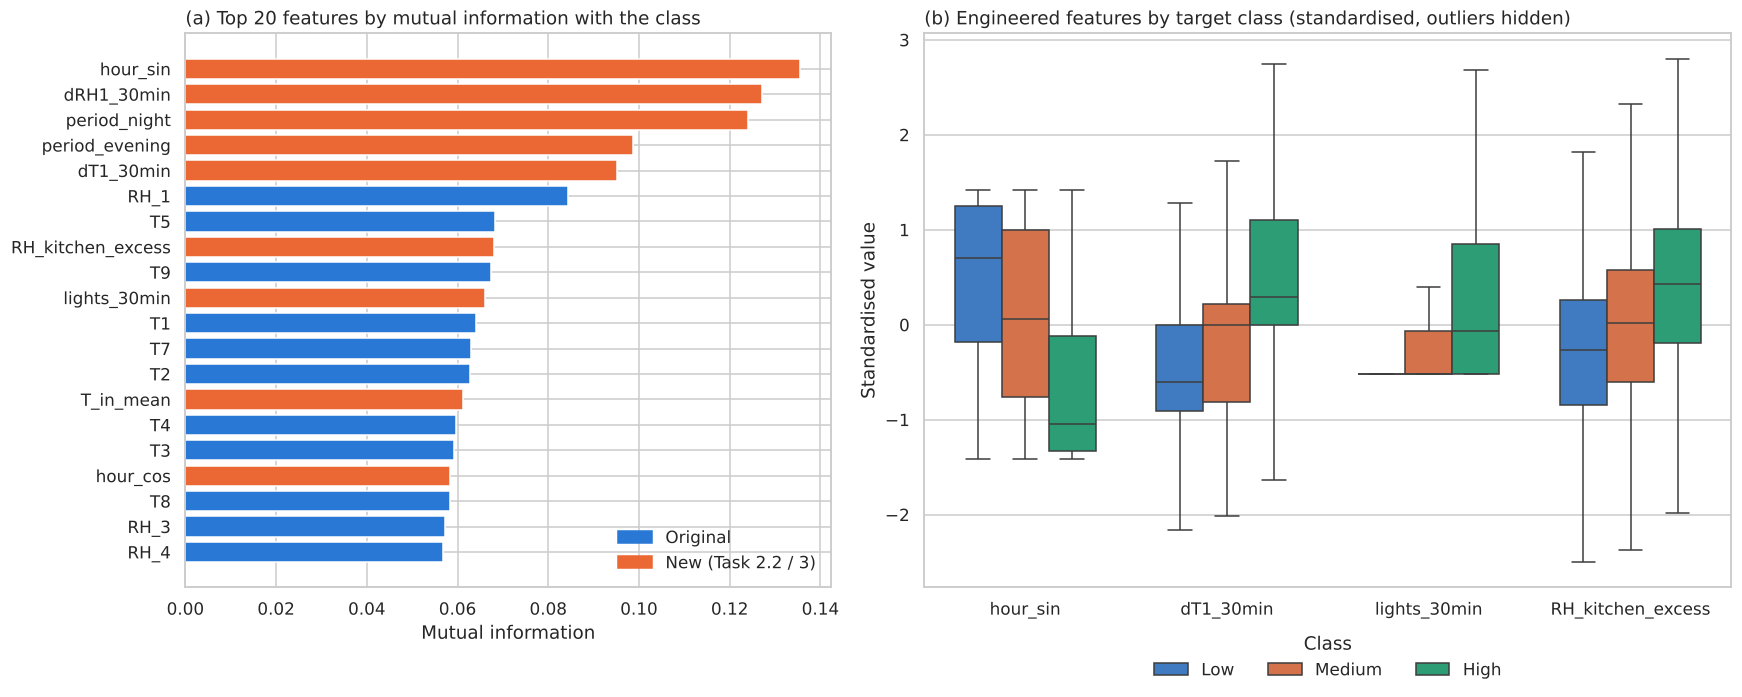

In [12]:
# Ranking of all features by mutual information with the class (orange = new feature)
mi_all = pd.concat([mi_orig, validation["mutual_info_vs_class"]]).sort_values(ascending=False).head(20)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].barh(mi_all.index, mi_all.values, color=[COLOR_SECOND if c in NEW_FEATURES else COLOR_MAIN for c in mi_all.index])
axes[0].set_title("(a) Top 20 features by mutual information with the class", loc="left")
axes[0].set_xlabel("Mutual information")
axes[0].legend(handles=[Patch(color=COLOR_MAIN, label="Original"), Patch(color=COLOR_SECOND, label="New (Task 2.2 / 3)")],
               loc="lower right", frameon=False)

# Class-wise distributions of four engineered features
show = ["hour_sin", "dT1_30min", "lights_30min", "RH_kitchen_excess"]
long = df[show + [CLASS_COL]].melt(id_vars=CLASS_COL, var_name="feature", value_name="value")
long["value"] = long.groupby("feature")["value"].transform(lambda s: (s - s.mean()) / s.std())   # common scale for display
sns.boxplot(data=long, x="feature", y="value", hue=CLASS_COL, palette=CLASS_PALETTE, ax=axes[1],
            showfliers=False, width=0.7, linewidth=1)
axes[1].set_title("(b) Engineered features by target class (standardised, outliers hidden)", loc="left")
axes[1].set_xlabel("")
axes[1].set_ylabel("Standardised value")
axes[1].legend(title="Class", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncols=3)
fig.tight_layout()
save_fig(fig, "pa2_task3_feature_validation")
plt.show()

### 3.2 Top correlations, multicollinearity and scaling of the new features

In [13]:
ALL_FEATURES = ORIGINAL_FEATURES + NEW_FEATURES
pearson_all = df[ALL_FEATURES].corrwith(df[TARGET])
top_corr = pd.DataFrame({"pearson_r": pearson_all, "abs_r": pearson_all.abs(),
                         "type": ["new" if c in NEW_FEATURES else "original" for c in ALL_FEATURES]}).sort_values("abs_r", ascending=False)
display(top_corr.head(10).round(3))

# Multicollinearity involving the new features
corr_all = df[ALL_FEATURES].corr()
pairs = [(a, b, corr_all.loc[a, b]) for a in NEW_FEATURES for b in ALL_FEATURES
         if a != b and abs(corr_all.loc[a, b]) >= 0.8 and not (b in NEW_FEATURES and NEW_FEATURES.index(b) < NEW_FEATURES.index(a))]
collinear_new = pd.DataFrame(pairs, columns=["new_feature", "other_feature", "pearson_r"]).sort_values("pearson_r", key=abs, ascending=False)
display(collinear_new.round(3).reset_index(drop=True))

# Scaling plan for all features (original + new), using the same rules as Task 2.1
scaling_plan_all = scaling_table(df, ALL_FEATURES)
display(scaling_plan_all.loc[NEW_FEATURES])
print(scaling_plan_all["final_scaler"].value_counts().to_string())

,pearson_r,abs_r,type
dT1_30min,0.298,0.298,new
period_night,-0.265,0.265,new
hour_sin,-0.260,0.260,new
period_evening,0.230,0.230,new
RH_kitchen_excess,0.207,0.207,new
hour_cos,-0.204,0.204,new
lights_30min,0.204,0.204,new
lights_on,0.200,0.200,new
lights,0.197,0.197,original
RH_out,-0.152,0.152,original


,new_feature,other_feature,pearson_r
0,T_in_mean,T9,0.955
1,T_in_out_diff,T_out,-0.954
2,T_in_mean,T1,0.948
3,T_in_mean,T5,0.944
4,T_in_mean,T4,0.941
5,T_in_mean,T7,0.941
6,T_in_mean,T3,0.937
7,T_in_out_diff,T6,-0.928
8,RH_in_mean,RH_4,0.925
9,lights_30min,lights,0.913


,skew,IQR_outlier_pct,zero_pct,rule,brief_scaler,final_scaler
feature,,,,,,
hour_sin,0.00,0.00,0.7,binary / cyclic,passthrough,passthrough
hour_cos,0.00,0.00,0.0,binary / cyclic,passthrough,passthrough
is_weekend,1.00,0.00,72.3,binary / cyclic,passthrough,passthrough
period_night,1.16,NaN,75.0,binary / cyclic,passthrough,passthrough
period_morning,1.16,NaN,75.0,binary / cyclic,passthrough,passthrough
period_afternoon,1.44,NaN,79.2,binary / cyclic,passthrough,passthrough
period_evening,1.43,NaN,79.1,binary / cyclic,passthrough,passthrough
period_late_evening,3.02,NaN,91.7,binary / cyclic,passthrough,passthrough
lights_on,1.30,NaN,77.3,binary / cyclic,passthrough,passthrough


final_scaler
StandardScaler      19
PowerTransformer    14
passthrough          9


### 3.3 Task 3 observations
- **The new features carry more signal than the original sensors.** Eight of the ten features most correlated with the target are new: `dT1_30min` has r = +0.298, compared with +0.197 for `lights`, the best original feature. On mutual information, `hour_sin` (0.136), `dRH1_30min` (0.127), `period_night` (0.124), `period_evening` (0.099) and `dT1_30min` (0.095) all exceed the best original feature (`RH_1`, 0.084).
- **The class medians move in the expected direction:** `hour_sin` falls from 0.50 (Low) to 0.04 (Medium) and −0.74 (High), because High readings occur in the afternoon and evening. `RH_kitchen_excess` rises from −1.51 to −0.92 and −0.09 (the kitchen becomes humid relative to the house while cooking), `lights_30min` is 0 for Low and Medium but 10 Wh for High, and the kitchen temperature tends to rise before High readings (`dT1_30min` median +0.03 °C vs −0.07 °C for Low).
- **Non-monotonic signal:** `dRH1_30min` has the second-highest mutual information but almost no rank correlation (ρ = −0.075). Kitchen humidity both rises (steam) and falls (ventilation, door opening) around cooking, so a large change in *either* direction indicates activity. Linear tests would miss this feature.
- **Weak features:** `is_weekend` (MI 0.006) and `period_morning` (0.003) add little, which confirms the weak weekday effect found in PA1 §5.2.1. They are kept for transparency, and Task 8 lets the data decide.
- **Multicollinearity:** the aggregates are collinear with their parts by design (`T_in_mean` vs `T9`: r = 0.955; `RH_in_mean` vs `RH_4`: 0.925), `T_in_out_diff` mirrors `T_out` (r = −0.954), and `lights_30min` follows `lights` (0.913). This redundancy does not hurt Decision Trees, but it motivates the feature selection and PCA steps for the SVM (Tasks 8–9).
- **Scaling of the new features:** the same rules give StandardScaler for 5 of them, the power transform for 5 skewed, outlier-heavy or zero-inflated features, and passthrough for 8 binary or cyclic features.

## 4. Task 4 – Decision Tree Modelling on Five Feature Sets
Following Studio 3 (Activity 1), five Decision Trees are built so that each comparison isolates **one preprocessing step**:

| Model | Feature set | Normalised | Inputs | Comparison it supports |
|---|---|---|---|---|
| Model 1 | Original features | No | 24 | baseline |
| Model 2 | Original features | Yes (final per-feature plan, Task 2) | 24 | normalisation (1 vs 2) |
| Model 3 | Original + engineered features | Yes | 42 | feature engineering (2 vs 3) |
| Model 4 | Selected features | Yes | 13 | feature selection (3 vs 4) |
| Model 5 | Selected features | No | 13 | normalisation on the selected set (4 vs 5) |

The **selected features** are chosen from engineering knowledge and the EDA (brief: "domain-selected features"): time of day (`hour_sin`, `hour_cos`), occupancy (`lights_30min`), kitchen activity (`dT1_30min`, `dRH1_30min`, `RH_kitchen_excess`), the living room (`T2`, top-3 correlated in PA1 §5.2), the laundry room (`T3`, ranked high in the original study), the bathroom (`RH_5`, `dRH5_30min`), the thermal state of the house (`T_in_mean`) and the weather (`T_out`, `RH_out`).

**Link to the brief's feature-set ideas.** Models 1–2 use Set 1 (original features), Model 3 uses Set 3 (original + engineered) and Models 4–5 use Set 5 (domain-selected; with 13 of 42 inputs it is also the candidate minimal viable set, Set 6). The rubric allows at most five trees, so the other two ideas are covered later with the SVM: dimensionality reduction (Set 4) with PCA in Task 9, and selection by the strength of the relationship with the target (Set 2) with SelectKBest in Task 8.

**Normalisation without data leakage.** In Studio 2/3 the normalised feature sets are saved as separate CSV files. Here the scaling is a step of a scikit-learn pipeline, so each scaler is fitted on the training rows only (and refitted in every CV fold), and the test data never influences the scaling. Every tree is evaluated on the same 70/30 split (Studio 3) and, in addition, with 5-fold CV.

### 4.1 Modelling dataset: shuffled and saved (Studio 3)
As in Studio 3 (Activity 3), the modelling data (all features + target) is **shuffled once and saved to a separate CSV file**. Every model in Tasks 4–10 reads this file and uses the same stratified 70/30 split. Cross-validation uses 5 consecutive stratified folds of the shuffled file.

In [14]:
SHUFFLED_PATH = Path("data") / "shuffled_modelling_data.csv.gz"     # compressed CSV
shuffled = df[["date"] + ALL_FEATURES + [TARGET, CLASS_COL]].sample(frac=1, random_state=RANDOM_STATE)
shuffled.to_csv(SHUFFLED_PATH, index=False)

# Read the saved file back and use it for all models
model_df = pd.read_csv(SHUFFLED_PATH, parse_dates=["date"])
y_model = pd.Series(pd.Categorical(model_df[CLASS_COL], categories=CLASS_LABELS, ordered=True).codes, name="class")
print(f"Saved and reloaded {SHUFFLED_PATH} – {model_df.shape[0]:,} rows x {model_df.shape[1]} columns")
display(model_df[["date", TARGET, CLASS_COL]].head(3))

train_idx, test_idx = train_test_split(np.arange(len(model_df)), test_size=TEST_SIZE,
                                       stratify=y_model, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=N_FOLDS)       # the data is already shuffled, so the folds are taken in order
print(f"Training rows: {len(train_idx):,} | test rows: {len(test_idx):,} | CV: {N_FOLDS} stratified folds")

Saved and reloaded data/shuffled_modelling_data.csv.gz – 19,735 rows x 45 columns


,date,Appliances,Appliances_class
0,2016-03-14 01:40:00,40,Low
1,2016-01-30 20:00:00,90,High
2,2016-03-15 03:00:00,50,Low


Training rows: 13,814 | test rows: 5,921 | CV: 5 stratified folds


In [15]:
SELECTED_FEATURES = ["hour_sin", "hour_cos", "lights_30min", "dT1_30min", "dRH1_30min", "RH_kitchen_excess",
                     "T2", "T3", "RH_5", "dRH5_30min", "T_in_mean", "T_out", "RH_out"]

DT_MODELS = {
    "Model 1: Original (raw)": (ORIGINAL_FEATURES, False),
    "Model 2: Original (normalised)": (ORIGINAL_FEATURES, True),
    "Model 3: Original + engineered (normalised)": (ALL_FEATURES, True),
    "Model 4: Selected (normalised)": (SELECTED_FEATURES, True),
    "Model 5: Selected (raw)": (SELECTED_FEATURES, False),
}


def make_dt(columns, normalised):
    """Decision Tree, optionally preceded by the final per-feature scaling from Task 2."""
    tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
    if not normalised:
        return tree
    return Pipeline([("pre", make_preprocessor(columns, scaling_plan_all)), ("dt", tree)])


dt_fitted, dt_rows = {}, []
for name, (cols, normalised) in DT_MODELS.items():
    X = model_df[cols]
    model = make_dt(cols, normalised).fit(X.iloc[train_idx], y_model.iloc[train_idx])
    tree = model[-1] if isinstance(model, Pipeline) else model
    pred = model.predict(X.iloc[test_idx])
    # 5-fold CV as well: one 70/30 split of a single unpruned tree is noisy, CV shows whether a difference is real
    cv_scores = cross_val_score(make_dt(cols, normalised), X, y_model, cv=cv, n_jobs=N_JOBS)
    dt_fitted[name] = model
    dt_rows.append({"model": name, "inputs": len(cols), "normalised": "yes" if normalised else "no",
                    "train_accuracy": accuracy_score(y_model.iloc[train_idx], model.predict(X.iloc[train_idx])),
                    "test_accuracy": accuracy_score(y_model.iloc[test_idx], pred),
                    "test_macro_F1": f1_score(y_model.iloc[test_idx], pred, average="macro"),
                    "cv_mean": cv_scores.mean(), "cv_std": cv_scores.std(),
                    "tree_depth": tree.get_depth(), "n_leaves": tree.get_n_leaves()})
dt_results = pd.DataFrame(dt_rows).set_index("model")
display(dt_results.round(4))
print(f"Highest 70/30 split accuracy: {dt_results['test_accuracy'].idxmax()} ({dt_results['test_accuracy'].max():.4f})")
print(f"Highest 5-fold CV accuracy:   {dt_results['cv_mean'].idxmax()} ({dt_results['cv_mean'].max():.4f})")

# The best tree is chosen on CV (average of 5 test sets) because the split differences are smaller than the CV std
best_dt_name = dt_results["cv_mean"].idxmax()
print(f"Best Decision Tree (chosen on CV): {best_dt_name}")

,inputs,normalised,train_accuracy,test_accuracy,test_macro_F1,cv_mean,cv_std,tree_depth,n_leaves
model,,,,,,,,,
Model 1: Original (raw),24,no,1.0,0.6845,0.6813,0.6890,0.0080,39,2955
Model 2: Original (normalised),24,yes,1.0,0.6879,0.6843,0.6883,0.0083,41,2954
Model 3: Original + engineered (normalised),42,yes,1.0,0.6815,0.6782,0.6927,0.0081,37,2593
Model 4: Selected (normalised),13,yes,1.0,0.6656,0.6629,0.6725,0.0048,36,2962
Model 5: Selected (raw),13,no,1.0,0.6641,0.6624,0.6752,0.0046,36,2965


Highest 70/30 split accuracy: Model 2: Original (normalised) (0.6879)
Highest 5-fold CV accuracy:   Model 3: Original + engineered (normalised) (0.6927)
Best Decision Tree (chosen on CV): Model 3: Original + engineered (normalised)


,importance
hour_sin,0.1332
hour_cos,0.0748
RH_kitchen_excess,0.0381
T5,0.0363
T8,0.0353
Press_mm_hg,0.0352
dRH5_30min,0.0335
dRH1_30min,0.0320
T_in_spread,0.0301
lights_30min,0.0275


Share of total importance from new features: 48.8% (18 of 42 features)


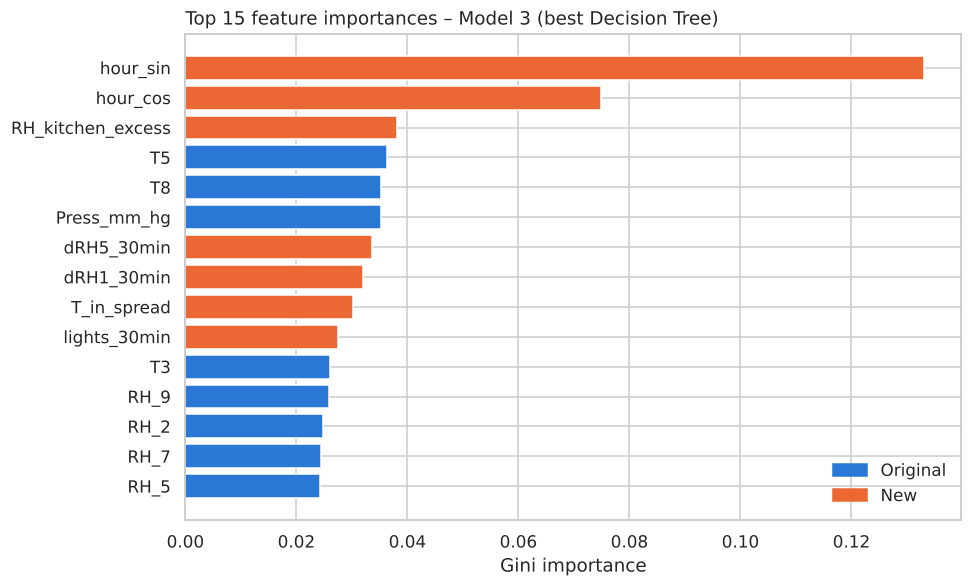

In [16]:
# Feature importance of the best Decision Tree
best_dt = dt_fitted[best_dt_name]
if isinstance(best_dt, Pipeline):
    names = best_dt.named_steps["pre"].get_feature_names_out()     # column order after the ColumnTransformer
    importances = pd.Series(best_dt[-1].feature_importances_, index=names)
else:
    importances = pd.Series(best_dt.feature_importances_, index=DT_MODELS[best_dt_name][0])
importances = importances.sort_values(ascending=False)
display(importances.head(15).round(4).to_frame("importance"))
print(f"Share of total importance from new features: {importances[importances.index.isin(NEW_FEATURES)].sum():.1%} "
      f"({importances.index.isin(NEW_FEATURES).sum()} of {len(importances)} features)")

top_imp = importances.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_imp.index, top_imp.values, color=[COLOR_SECOND if c in NEW_FEATURES else COLOR_MAIN for c in top_imp.index])
ax.set_title(f"Top 15 feature importances – {best_dt_name.split(':')[0]} (best Decision Tree)", loc="left")
ax.set_xlabel("Gini importance")
ax.legend(handles=[Patch(color=COLOR_MAIN, label="Original"), Patch(color=COLOR_SECOND, label="New")],
          loc="lower right", frameon=False)
fig.tight_layout()
save_fig(fig, "pa2_task4_dt_feature_importance")
plt.show()

## 5. Task 5 – Results Comparison Table (Decision Trees)
First summary table in the Studio 3 format (accuracy in %). The 5-fold CV row is added because the differences between some models are smaller than the variation between folds; the detailed results follow.

,Model 1,Model 2,Model 3,Model 4,Model 5
Accuracy (%) – 70/30 split,68.45,68.79,68.15,66.56,66.41
Accuracy (%) – 5-fold CV,68.90,68.83,69.27,67.25,67.52


,Inputs,Normalised,Test accuracy (70/30),CV mean,CV std,Test macro-F1,Train accuracy,Tree depth,Leaves
model,,,,,,,,,
Model 1: Original (raw),24,no,0.6845,0.6890,0.0080,0.6813,1.0000,39,2955
Model 2: Original (normalised),24,yes,0.6879,0.6883,0.0083,0.6843,1.0000,41,2954
Model 3: Original + engineered (normalised),42,yes,0.6815,0.6927,0.0081,0.6782,1.0000,37,2593
Model 4: Selected (normalised),13,yes,0.6656,0.6725,0.0048,0.6629,1.0000,36,2962
Model 5: Selected (raw),13,no,0.6641,0.6752,0.0046,0.6624,1.0000,36,2965


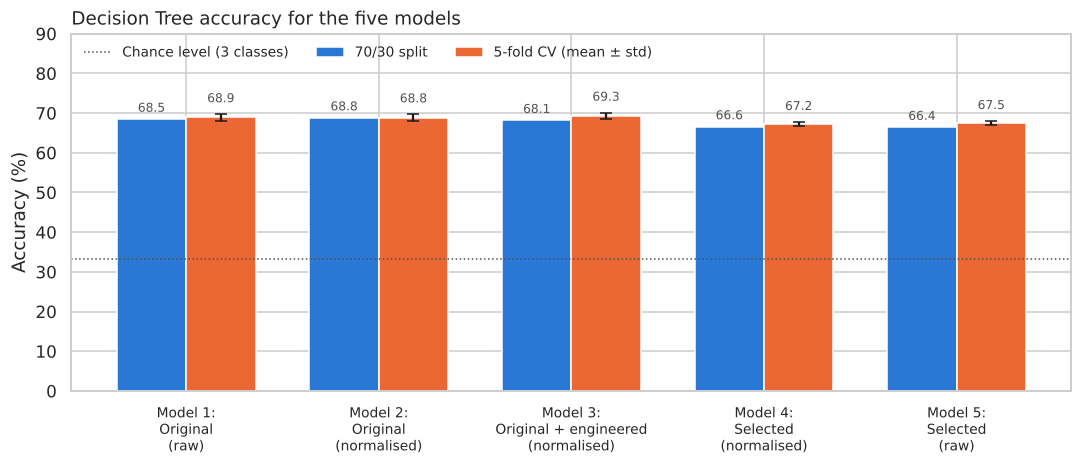

In [17]:
studio_table = pd.DataFrame([(dt_results["test_accuracy"] * 100).round(2).values,
                             (dt_results["cv_mean"] * 100).round(2).values],
                            columns=[n.split(":")[0] for n in dt_results.index],
                            index=["Accuracy (%) – 70/30 split", "Accuracy (%) – 5-fold CV"])
display(studio_table)

dt_table = dt_results[["inputs", "normalised", "test_accuracy", "cv_mean", "cv_std", "test_macro_F1", "train_accuracy",
                       "tree_depth", "n_leaves"]].copy()
dt_table.columns = ["Inputs", "Normalised", "Test accuracy (70/30)", "CV mean", "CV std", "Test macro-F1", "Train accuracy",
                    "Tree depth", "Leaves"]
display(dt_table.style.format({c: "{:.4f}" for c in ["Test accuracy (70/30)", "CV mean", "CV std", "Test macro-F1", "Train accuracy"]})
        .highlight_max(subset=["Test accuracy (70/30)", "CV mean"], color="#d6e6f8"))

fig, ax = plt.subplots(figsize=(10, 4.4))
names = [n.replace(": ", ":\n").replace(" (", "\n(") for n in dt_table.index]
x = np.arange(len(names))
w = 0.36
b1 = ax.bar(x - w / 2, dt_table["Test accuracy (70/30)"] * 100, width=w, color=COLOR_MAIN, label="70/30 split")
b2 = ax.bar(x + w / 2, dt_table["CV mean"] * 100, width=w, color=COLOR_SECOND, yerr=dt_table["CV std"] * 100, capsize=4,
            label="5-fold CV (mean ± std)")
ax.bar_label(b1, labels=[f"{v * 100:.1f}" for v in dt_table["Test accuracy (70/30)"]], padding=3, color=COLOR_TEXT, fontsize=8)
ax.bar_label(b2, labels=[f"{v * 100:.1f}" for v in dt_table["CV mean"]], padding=6, color=COLOR_TEXT, fontsize=8)
ax.axhline(100 / 3, color=COLOR_TEXT, linestyle=":", linewidth=1, label="Chance level (3 classes)")
ax.set_xticks(x, names, fontsize=9)
ax.set_ylim(0, 90)
ax.set_title("Decision Tree accuracy for the five models", loc="left")
ax.set_ylabel("Accuracy (%)")
ax.legend(loc="upper left", frameon=False, fontsize=9, ncols=3)
fig.tight_layout()
save_fig(fig, "pa2_task5_dt_comparison")
plt.show()

### 5.1 Reflection questions (Studio 3)
**1. Which feature set performed best? Why do you think that is?** On the 70/30 split, Model 2 (original, normalised) scores highest (68.79%). However, Models 1–3 lie within 0.64 pp of each other (68.15–68.79%), which is less than the variation between CV folds (standard deviation ≈ 0.8 pp). The 5-fold CV averages five different test sets and ranks **Model 3 (original + engineered, normalised) first with 69.27% ± 0.81**, ahead of Model 1 (68.90%) and Model 2 (68.83%). Model 3 is therefore taken as the best tree. It is the only model with direct information about the household routine: `hour_sin` and `hour_cos` are its two most important features (0.133 and 0.075), and the 18 new features account for **48.8%** of the total importance. The gain is small because a fully grown tree can partly rebuild the time of day from the original sensors, since outdoor temperature and humidity follow the daily cycle (PA1 §5.2.1).

**2. Did normalisation improve performance? (Model 1 vs Model 2)** No. Accuracy changes by +0.34 pp on the split (68.45% → 68.79%) and by −0.07 pp in CV (68.90% → 68.83%), so the sign depends on the evaluation and the difference is noise. A Decision Tree splits on one feature at a time. StandardScaler and the Yeo-Johnson transform are monotonic: they keep the order of the values, so the tree can build the same partitions. The tiny differences come from where the threshold lands. The tree places it halfway between two neighbouring training values, and after a non-linear transform "halfway" corresponds to a slightly different raw value, so a few test readings fall on the other side.

**3. Did feature engineering help? (Model 2 vs Model 3)** Only slightly for the tree: −0.64 pp on the split (68.79% → 68.15%) but +0.44 pp in CV (68.83% → 69.27%). The tree does use the new features heavily (48.8% of the importance) and needs fewer leaves (2,593 vs 2,954), so it finds a simpler description of the data with the same accuracy. The engineered features matter much more for the SVM (+3.4 pp, Task 10.1), and the five features with the highest F-scores are all engineered (Task 8). An unpruned tree also gets more ways to overfit when more features are added.

**4. Was feature selection effective? (Model 3 vs Model 4)** It was effective as a simplification, not as an improvement. Reducing 42 inputs to the 13 domain-selected features costs 1.59 pp on the split (68.15% → 66.56%) and 2.02 pp in CV (69.27% → 67.25%). The model keeps about 97% of the accuracy with 31% of the inputs. The removed features (for example `RH_8`, `RH_9` and `Press_mm_hg`, which were among the most important features of Model 2) still carry some information that the tree loses.

**5. Is normalisation always necessary? (Model 4 vs Model 5)** No, not for trees: 66.56% (normalised) vs 66.41% (raw) on the split, and 67.25% vs 67.52% in CV. The sign flips again, so the difference is noise, which confirms Question 2 on a second feature set. Normalisation is necessary for distance-based or gradient-based models such as SVM, k-NN and neural networks. The same SVM drops from 66.5% to 51.0% without normalisation (Task 10.1). For a tree, scaling can be skipped, which keeps the split thresholds in physical units (°C, %, Wh) and makes the tree easier to read.

**6. What pattern do you observe across the five models?**
- **What the features contain matters more than how they are scaled.** The two pairs that differ only in normalisation (1/2 and 4/5) are within 0.35 pp of each other, while the pairs that differ in their features differ by 1.5–2 pp.
- **All trees overfit strongly.** Each reaches 100% training accuracy with a depth of 36–41 and 2,593–2,965 leaves, so there is a gap of 31–34 pp between training and test accuracy.
- **All five models are close** (66.4–68.8% on the split). The fully grown single tree is the limiting factor, more than the features. Pruning, ensembles or a smoother model (SVM, Task 6) are needed to go further.
- **Medium is the hardest class** for the best tree: recall 0.53, compared with 0.71 for Low and 0.80 for High.

## 6. Task 6 – Model Improvement with SVM
An SVM (default RBF kernel, `C = 1`, `gamma = "scale"`) is trained on **all 42 prepared features** (original + engineered, final per-feature scaling inside the pipeline), so that Tasks 8 and 9 can select or reduce from the full set. Following Studio 3, it is evaluated on the shuffled file with:
- a **70/30 train-test split** (the same split as the Decision Trees), and
- **5-fold stratified cross-validation** (each fold refits the scaler and the SVM).

In [18]:
SVM_FEATURES = ALL_FEATURES
X_svm = model_df[SVM_FEATURES]


def svm_pipeline(extra_steps=(), **svc_params):
    """Scaling (final plan) -> optional selection/PCA -> SVM."""
    return Pipeline([("pre", make_preprocessor(SVM_FEATURES, scaling_plan_all)), *extra_steps, ("svc", SVC(**svc_params))])


def evaluate(model, label):
    """70/30 split accuracy and macro-F1, plus 5-fold CV accuracy (mean and std)."""
    start = time.time()
    model.fit(X_svm.iloc[train_idx], y_model.iloc[train_idx])
    pred = model.predict(X_svm.iloc[test_idx])
    cv_scores = cross_val_score(model, X_svm, y_model, cv=cv, scoring="accuracy", n_jobs=N_JOBS)
    result = {"model": label, "split_accuracy": accuracy_score(y_model.iloc[test_idx], pred),
              "split_macro_F1": f1_score(y_model.iloc[test_idx], pred, average="macro"),
              "cv_mean": cv_scores.mean(), "cv_std": cv_scores.std(), "seconds": time.time() - start}
    print(f"{label}: split {result['split_accuracy']:.4f} | CV {result['cv_mean']:.4f} ± {result['cv_std']:.4f} "
          f"| {result['seconds']:.0f} s")
    return result, model, pred


svm_base_result, svm_base, svm_base_pred = evaluate(svm_pipeline(), "SVM baseline (RBF, C=1, gamma='scale')")
print()
print(classification_report(y_model.iloc[test_idx], svm_base_pred, target_names=CLASS_LABELS, digits=3))

# Decision Tree on the same 42 features with the same split and CV folds, for a fair comparison
m3 = dt_results.loc["Model 3: Original + engineered (normalised)"]
print(f"Decision Tree on the same features (Model 3): split {m3['test_accuracy']:.4f} | CV {m3['cv_mean']:.4f} ± {m3['cv_std']:.4f}")

SVM baseline (RBF, C=1, gamma='scale'): split 0.6985 | CV 0.7008 ± 0.0038 | 51 s

              precision    recall  f1-score   support

         Low      0.708     0.793     0.748      2239
      Medium      0.580     0.466     0.517      1814
        High      0.775     0.810     0.792      1868

    accuracy                          0.699      5921
   macro avg      0.688     0.690     0.686      5921
weighted avg      0.690     0.699     0.691      5921

Decision Tree on the same features (Model 3): split 0.6815 | CV 0.6927 ± 0.0081


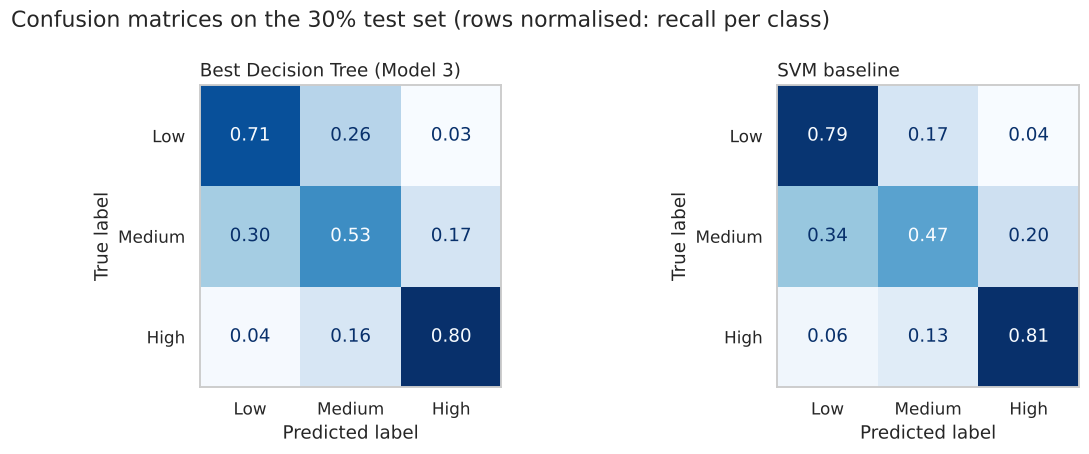

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
best_dt_pred = dt_fitted[best_dt_name].predict(model_df[DT_MODELS[best_dt_name][0]].iloc[test_idx])
ConfusionMatrixDisplay.from_predictions(y_model.iloc[test_idx], best_dt_pred, display_labels=CLASS_LABELS, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Best Decision Tree ({best_dt_name.split(':')[0]})", loc="left")
ConfusionMatrixDisplay.from_predictions(y_model.iloc[test_idx], svm_base_pred, display_labels=CLASS_LABELS, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("SVM baseline", loc="left")
for ax in axes:
    ax.grid(False)
fig.suptitle("Confusion matrices on the 30% test set (rows normalised: recall per class)", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "pa2_task6_confusion_matrices")
plt.show()

### 6.1 Task 6 observations
- **SVM vs Decision Tree:** with the same 42 features, the same split and the same folds, the baseline SVM reaches **69.85%** on the 70/30 split (+1.70 pp over Model 3's 68.15%) and **70.08% ± 0.38** in 5-fold CV (+0.81 pp over 69.27% ± 0.81). The smooth RBF decision boundary generalises better than a fully grown tree, which memorises the training data.
- **Stability:** the split and CV results agree within 0.25 pp, and the CV standard deviation of the SVM is half that of the tree (0.38 vs 0.81 pp), so the SVM is also the more stable model.
- **Errors by class:** Low (recall 0.79) and High (0.81) are recognised well, but Medium is not (0.47); 34% of the Medium readings are predicted as Low. Compared with the best tree, the SVM is better on Low (0.79 vs 0.71) and High (0.81 vs 0.80) but worse on Medium (0.47 vs 0.53): with default settings, the smooth boundary pushes the narrow middle class towards its neighbours. Confusions between the two extreme classes are rare (4–6%), so the errors respect the ordinal structure of the classes. Medium spans only 60–80 Wh and lies between the other two classes, as expected in Task 1.
- **Model choice:** the target is categorical, so a support vector **classifier** (SVC) is used, not SVR.

## 7. Task 7 – Hyperparameter Tuning
Following Studio 3 (Activity 4): (1) try different kernels and select one, (2) tune its hyperparameters with GridSearchCV, (3) re-evaluate the tuned SVM on both the 70/30 split and 5-fold CV.

### 7.1 Kernel selection

In [20]:
kernel_rows = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    start = time.time()
    model = svm_pipeline(kernel=kernel).fit(X_svm.iloc[train_idx], y_model.iloc[train_idx])
    kernel_rows.append({"kernel": kernel, "split_accuracy": model.score(X_svm.iloc[test_idx], y_model.iloc[test_idx]),
                        "fit_seconds": time.time() - start})
kernel_results = pd.DataFrame(kernel_rows).set_index("kernel")
KERNEL = kernel_results["split_accuracy"].idxmax()
display(kernel_results.round(4))
print(f"Selected kernel: {KERNEL}")

,split_accuracy,fit_seconds
kernel,,
linear,0.6257,15.5244
poly,0.6820,9.7348
rbf,0.6985,11.3298
sigmoid,0.4893,11.6968


Selected kernel: rbf


### 7.2 GridSearchCV
For the selected kernel, two hyperparameters are tuned:
- **C** – penalty for misclassified training points (low C = smoother boundary, high C = fits the training data more closely).
- **gamma** – how far the influence of one training point reaches (high gamma = very local, wiggly boundary).

The grid covers three orders of magnitude for both. GridSearchCV runs 5-fold stratified CV **on the training split only**, so the test set stays untouched. *(Runtime: several minutes – 12 combinations × 5 folds.)*

In [21]:
PARAM_GRID = {"svc__kernel": [KERNEL], "svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]}
grid = GridSearchCV(svm_pipeline(), PARAM_GRID, cv=StratifiedKFold(n_splits=N_FOLDS), scoring="accuracy",
                    n_jobs=N_JOBS, refit=True)
start = time.time()
grid.fit(X_svm.iloc[train_idx], y_model.iloc[train_idx])
print(f"Grid search finished in {time.time() - start:.0f} s")
BEST_PARAMS = {k.replace("svc__", ""): v for k, v in grid.best_params_.items()}
print(f"Best parameters: {BEST_PARAMS} | mean CV accuracy on the training split: {grid.best_score_:.4f}")

grid_scores = pd.DataFrame(grid.cv_results_)[["param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score"]]
grid_scores.columns = ["C", "gamma", "mean_cv_accuracy", "std_cv_accuracy"]
display(grid_scores.sort_values("mean_cv_accuracy", ascending=False).round(4).reset_index(drop=True))

Grid search finished in 292 s
Best parameters: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'} | mean CV accuracy on the training split: 0.7177


,C,gamma,mean_cv_accuracy,std_cv_accuracy
0,10,0.1,0.7177,0.0089
1,1,0.1,0.7167,0.0074
2,10,scale,0.7141,0.0080
3,100,scale,0.7136,0.0078
4,100,0.01,0.7120,0.0100
5,100,0.1,0.7025,0.0073
6,1,1,0.6994,0.0073
7,10,0.01,0.6963,0.0088
8,1,scale,0.6931,0.0079
9,10,1,0.6886,0.0075


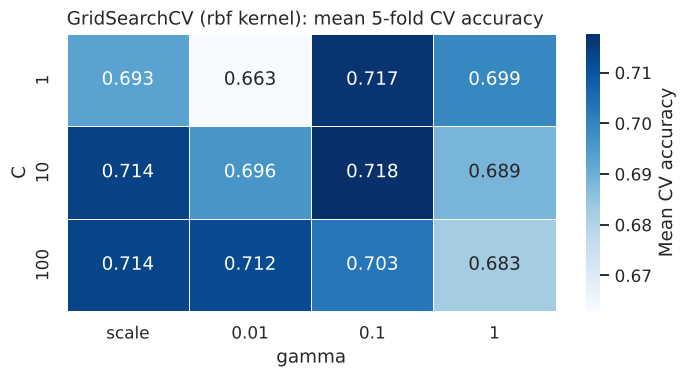

SVM tuned {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}: split 0.7256 | CV 0.7343 ± 0.0088 | 54 s
Improvement over the baseline: split +2.70 pp | CV +3.35 pp


In [22]:
heat = grid_scores.assign(gamma=grid_scores["gamma"].astype(str)).pivot(index="C", columns="gamma", values="mean_cv_accuracy")
heat = heat[[g for g in ["scale", "0.01", "0.1", "1"] if g in heat.columns]]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "Mean CV accuracy"}, linewidths=0.5, ax=ax)
ax.set_title(f"GridSearchCV ({KERNEL} kernel): mean 5-fold CV accuracy", loc="left")
ax.set_xlabel("gamma")
ax.set_ylabel("C")
fig.tight_layout()
save_fig(fig, "pa2_task7_grid_heatmap")
plt.show()

svm_tuned_result, svm_tuned, _ = evaluate(svm_pipeline(**BEST_PARAMS), f"SVM tuned {BEST_PARAMS}")
print(f"Improvement over the baseline: split {100 * (svm_tuned_result['split_accuracy'] - svm_base_result['split_accuracy']):+.2f} pp | "
      f"CV {100 * (svm_tuned_result['cv_mean'] - svm_base_result['cv_mean']):+.2f} pp")

### 7.3 Task 7 observations
- **Kernel selection:** with default settings, the RBF kernel performs best (69.85%), ahead of polynomial (68.20%), linear (62.57%) and sigmoid (48.93%). The linear kernel is 7.3 pp worse, so the classes are not linearly separable. For example, High consumption depends on the *combination* of time of day and activity (lights, kitchen changes), not on any single feature. The sigmoid kernel is far behind: it is not a valid (positive semi-definite) kernel for many settings, and it is only 11 pp above the majority baseline. **RBF is selected**: it is the most accurate and has only two hyperparameters to tune.
- **Grid search:** 3 values of C × 4 values of gamma = 12 combinations, each evaluated with 5-fold CV on the training split (60 fits, about 5 minutes). The best combination is **C = 10, gamma = 0.1**, with a mean CV accuracy of 71.77%. C = 1 with gamma = 0.1 is almost the same (71.67%), so **gamma is the parameter that matters**.
- **Interpretation (bias–variance trade-off):** the default `gamma = "scale"` equals ≈ 0.028 for these features, so the best gamma makes the boundary about 3.5 times more local. A boundary that is too local overfits: gamma = 1 gives 68.26–69.94%, and it gets worse as C grows. A boundary that is too smooth underfits: gamma = 0.01 with C = 1 gives 66.30%. A large C only helps when gamma is small (C = 100, gamma = 0.01: 71.20%) and hurts when gamma is large (C = 100, gamma = 0.1: 70.25%).
- **Improvement:** the tuned SVM reaches **72.56%** on the 70/30 split and **73.43% ± 0.88** in 5-fold CV, which is **+2.70 pp (split) and +3.35 pp (CV)** over the default SVM. The gain is mainly in the hardest class: Medium recall rises from 0.47 to 0.54, and High from 0.81 to 0.84. The CV accuracy on the full data (73.4%) is higher than the grid-search score (71.8%) because each fold trains on 15,788 rows instead of 11,051.

## 8. Task 8 – Feature Selection (SelectKBest)
`SelectKBest` with the ANOVA F-test (`f_classif`) ranks the scaled features by how strongly their mean differs between the three classes and keeps the best K. It runs inside the pipeline after scaling, so the ranking is learned from the training data only. The SVM uses the tuned hyperparameters from Task 7 (Studio 3, Activity 5). K is chosen by scanning several values on the 70/30 split.

K,5,10,15,20,25,30,35,42
split_accuracy,0.5732,0.6156,0.6806,0.708,0.72,0.7271,0.7291,0.7256


Best accuracy 0.7291 at K = 35; chosen K = 25 (smallest K within 1 pp of the best)


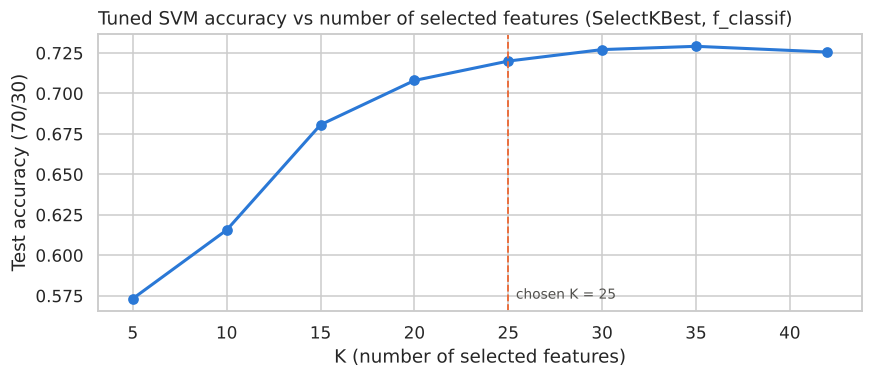

In [23]:
n_total = len(SVM_FEATURES)
K_VALUES = [k for k in [5, 10, 15, 20, 25, 30, 35] if k < n_total] + [n_total]
k_scan = []
for k in K_VALUES:
    model = svm_pipeline([("select", SelectKBest(f_classif, k=k))], **BEST_PARAMS)
    model.fit(X_svm.iloc[train_idx], y_model.iloc[train_idx])
    k_scan.append({"K": k, "split_accuracy": model.score(X_svm.iloc[test_idx], y_model.iloc[test_idx])})
k_scan = pd.DataFrame(k_scan).set_index("K")
display(k_scan.round(4).T)

# Smallest K within 1 percentage point of the best accuracy (simpler model, similar accuracy)
best_k_acc = k_scan["split_accuracy"].max()
BEST_K = int(k_scan.index[k_scan["split_accuracy"] >= best_k_acc - 0.01].min())
print(f"Best accuracy {best_k_acc:.4f} at K = {k_scan['split_accuracy'].idxmax()}; chosen K = {BEST_K} "
      f"(smallest K within 1 pp of the best)")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(k_scan.index, k_scan["split_accuracy"], marker="o", color=COLOR_MAIN, linewidth=2)
ax.axvline(BEST_K, color=COLOR_SECOND, linestyle="--", linewidth=1.2)
ax.annotate(f"chosen K = {BEST_K}", xy=(BEST_K, k_scan["split_accuracy"].min()), xytext=(5, 0),
            textcoords="offset points", color=COLOR_TEXT, fontsize=9)
ax.set_title("Tuned SVM accuracy vs number of selected features (SelectKBest, f_classif)", loc="left")
ax.set_xlabel("K (number of selected features)")
ax.set_ylabel("Test accuracy (70/30)")
fig.tight_layout()
save_fig(fig, "pa2_task8_k_scan")
plt.show()

In [24]:
svm_kbest_result, svm_kbest, _ = evaluate(svm_pipeline([("select", SelectKBest(f_classif, k=BEST_K))], **BEST_PARAMS),
                                          f"SVM tuned + SelectKBest (K={BEST_K})")
selector = svm_kbest.named_steps["select"]
scaled_names = svm_kbest.named_steps["pre"].get_feature_names_out()
selected = pd.DataFrame({"feature": scaled_names, "F_score": selector.scores_, "selected": selector.get_support()})
dropped = selected.loc[~selected["selected"], "feature"].tolist()
selected = selected[selected["selected"]].sort_values("F_score", ascending=False).drop(columns="selected")
selected["type"] = ["new" if f in NEW_FEATURES else "original" for f in selected["feature"]]
display(selected.round(1).reset_index(drop=True))
print(f"Features removed by SelectKBest ({len(dropped)}): {dropped}")

SVM tuned + SelectKBest (K=25): split 0.7200 | CV 0.7267 ± 0.0035 | 45 s


,feature,F_score,type
0,hour_sin,2008.6,new
1,period_evening,1837.2,new
2,period_night,1637.0,new
3,dT1_30min,1198.1,new
4,lights_30min,801.0,new
5,lights,680.9,original
6,lights_on,677.0,new
7,RH_kitchen_excess,645.0,new
8,T2,620.8,original
9,RH_out,550.6,original


Features removed by SelectKBest (17): ['RH_5', 'Windspeed', 'Visibility', 'T_in_spread', 'dRH1_30min', 'dRH5_30min', 'RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_7', 'Press_mm_hg', 'Tdewpoint', 'RH_in_mean', 'is_weekend', 'period_morning', 'period_afternoon']


### 8.1 Task 8 observations
- **Choice of K:** accuracy rises steeply up to K = 20 (K = 5: 57.32%, K = 10: 61.56%, K = 15: 68.06%, K = 20: 70.80%) and then levels off (K = 25: 72.00%, K = 30: 72.71%, K = 35: 72.91%, all 42: 72.56%). The best value, K = 35, is only 0.35 pp above using all features. **K = 25** is the smallest K within 1 pp of the best and is used. It gives **72.00% on the split and 72.67% ± 0.35 in CV**: −0.56 pp and −0.76 pp compared with the tuned SVM on all features, with **40% fewer inputs** (25 of 42) and the lowest CV standard deviation of all the SVM models.
- **Selected features:** the five highest F-scores belong to engineered features: `hour_sin` (2,009), `period_evening` (1,837), `period_night` (1,637), `dT1_30min` (1,198) and `lights_30min` (801). In total, 11 of the 25 selected features are new. This confirms the value of the feature engineering in Task 3.
- **Removed features (17):** mostly humidities (`RH_1`–`RH_5`, `RH_7`, `RH_in_mean`) and weather variables (`Windspeed`, `Visibility`, `Press_mm_hg`, `Tdewpoint`), plus `is_weekend`, `period_morning` and `period_afternoon`. This matches the weak correlations of these features in PA1 §5.2.
- **Limitation of the ANOVA F-test:** the F-test only compares the class *means*. It therefore removes `dRH1_30min`, which has the second-highest mutual information in Task 3 and is among the ten most important features of the best tree. Its effect is non-monotonic: kitchen humidity both rises and falls around cooking. A mutual-information score (`mutual_info_classif`) would be a better criterion for this non-linear problem.

## 9. Task 9 – Dimensionality Reduction (PCA)
PCA projects the scaled features onto uncorrelated components ordered by explained variance. It suits this dataset because of the strong multicollinearity found in PA1 §5.3 (35 pairs with |r| ≥ 0.8, 14 VIFs above 10). Studio 3 suggests the first 10 components "or choose based on the dataset"; here the number is chosen from the cumulative explained variance and checked against accuracy. The SVM uses the tuned hyperparameters from Task 7.

Components for 90% variance: 13 | for 95% variance: 17 (of 42 features)
First 5 components explain 70.6% of the variance; first 10 explain 84.9%


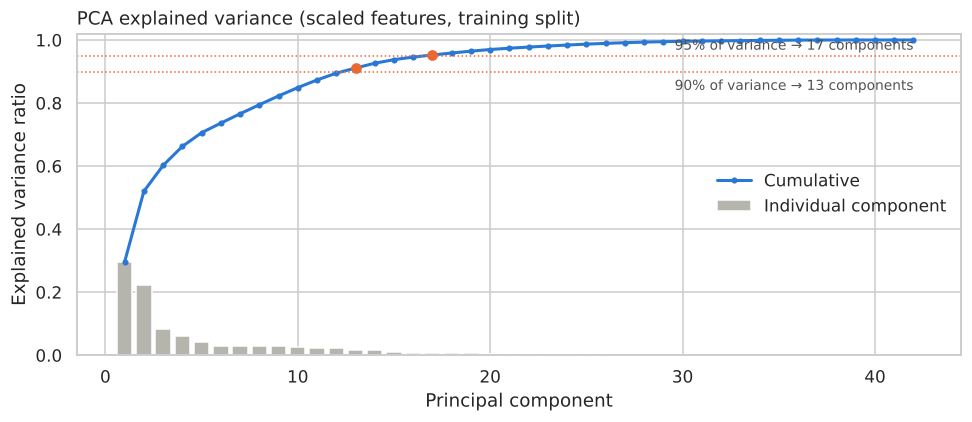

In [25]:
pca_full = Pipeline([("pre", make_preprocessor(SVM_FEATURES, scaling_plan_all)), ("pca", PCA(random_state=RANDOM_STATE))])
pca_full.fit(X_svm.iloc[train_idx])
explained = pca_full.named_steps["pca"].explained_variance_ratio_
cumulative = np.cumsum(explained)
N_90 = int(np.argmax(cumulative >= 0.90) + 1)
N_95 = int(np.argmax(cumulative >= 0.95) + 1)
print(f"Components for 90% variance: {N_90} | for 95% variance: {N_95} (of {len(explained)} features)")
print(f"First 5 components explain {cumulative[4]:.1%} of the variance; first 10 explain {cumulative[9]:.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
comp = np.arange(1, len(explained) + 1)
ax.bar(comp, explained, color=COLOR_GREY, label="Individual component")
ax.plot(comp, cumulative, color=COLOR_MAIN, marker="o", markersize=3, linewidth=2, label="Cumulative")
for level, n, dy in [(0.90, N_90, -12), (0.95, N_95, 4)]:
    ax.axhline(level, color=COLOR_SECOND, linestyle=":", linewidth=1)
    ax.plot([n], [cumulative[n - 1]], marker="o", color=COLOR_SECOND, markersize=6)
    ax.annotate(f"{level:.0%} of variance → {n} components", xy=(len(explained), level), xytext=(0, dy),
                textcoords="offset points", ha="right", fontsize=9, color=COLOR_TEXT)
ax.set_ylim(0, 1.02)
ax.set_title("PCA explained variance (scaled features, training split)", loc="left")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.legend(loc="center right", frameon=False)
fig.tight_layout()
save_fig(fig, "pa2_task9_pca_variance")
plt.show()

In [26]:
# Accuracy of the tuned SVM for different numbers of components (10 = Studio 3 default)
N_VALUES = sorted({5, 10, N_90, N_95, min(25, len(explained))})
pca_scan = []
for n in N_VALUES:
    model = svm_pipeline([("pca", PCA(n_components=n, random_state=RANDOM_STATE))], **BEST_PARAMS)
    model.fit(X_svm.iloc[train_idx], y_model.iloc[train_idx])
    pca_scan.append({"components": n, "variance_explained": cumulative[n - 1],
                     "split_accuracy": model.score(X_svm.iloc[test_idx], y_model.iloc[test_idx])})
pca_scan = pd.DataFrame(pca_scan).set_index("components")
display(pca_scan.round(4))

BEST_N = N_95   # 95% of the variance: keeps almost all information
svm_pca_result, svm_pca, _ = evaluate(svm_pipeline([("pca", PCA(n_components=BEST_N, random_state=RANDOM_STATE))], **BEST_PARAMS),
                                      f"SVM tuned + PCA ({BEST_N} components)")

,variance_explained,split_accuracy
components,,
5,0.7059,0.6512
10,0.8489,0.7043
13,0.9111,0.7166
17,0.9524,0.7264
25,0.9869,0.7245


SVM tuned + PCA (17 components): split 0.7264 | CV 0.7323 ± 0.0097 | 39 s


### 9.1 Task 9 observations
- **Explained variance:** the first 5 components explain 70.6% of the variance and the first 10 (the Studio 3 default) explain 84.9%. 13 components reach 90% and **17 components reach 95%** of the variance of the 42 scaled features. The data can be compressed this much because the indoor sensors are strongly collinear (PA1 §5.3).
- **Choice of the number of components:** accuracy rises with the number of components up to 17 and then stops (5: 65.12%, 10: 70.43%, 13: 71.66%, **17: 72.64%**, 25: 72.45%). The Studio default of 10 components would lose 2.2 pp, so the number is chosen from the dataset: **17 components (95% of the variance)**.
- **Result:** **72.64% on the split and 73.23% ± 0.97 in CV**, i.e. +0.08 pp and −0.20 pp compared with the tuned SVM on all 42 features. This is practically the same accuracy with 60% fewer inputs to the SVM.
- **Limitations:** PCA is unsupervised. It keeps directions of high variance, which do not have to be the most predictive ones, as the poor result with 5 components shows. Each component mixes all the sensors, so the model loses interpretability. Unlike feature selection, PCA does not reduce the number of sensors, because all 42 features are still needed to compute the components.

## 10. Task 10 – Final Results Table
Final summary in the Studio 3 format. "Original features" means the SVM with its **original (default) hyperparameters** on all 42 prepared features.

,Train-test split (%),Cross-validation (%),CV std (pp),Inputs,Split macro-F1
SVM model,,,,,
Original features,69.85,70.08,0.38,42,0.6858
With hyperparameter tuning,72.56,73.43,0.88,42,0.7193
With feature selection and hyperparameter tuning,72.00,72.67,0.35,25,0.7111
With PCA and hyperparameter tuning,72.64,73.23,0.97,17,0.7203


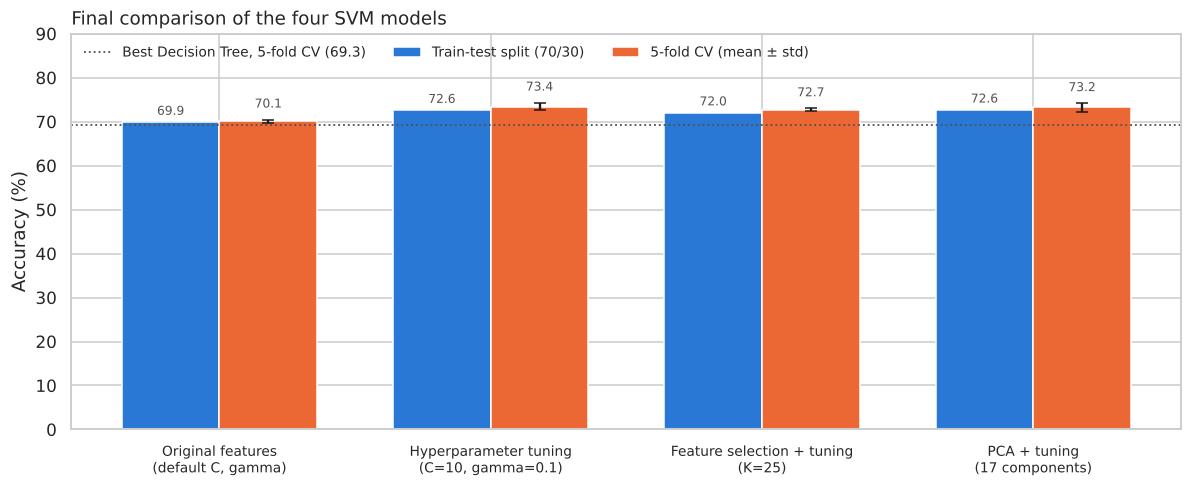

In [27]:
final = pd.DataFrame([svm_base_result, svm_tuned_result, svm_kbest_result, svm_pca_result])
final.index = ["Original features", "With hyperparameter tuning",
               "With feature selection and hyperparameter tuning", "With PCA and hyperparameter tuning"]
final.insert(0, "inputs", [len(SVM_FEATURES), len(SVM_FEATURES), BEST_K, BEST_N])
studio_final = pd.DataFrame({"Train-test split (%)": (final["split_accuracy"] * 100).round(2),
                             "Cross-validation (%)": (final["cv_mean"] * 100).round(2),
                             "CV std (pp)": (final["cv_std"] * 100).round(2),
                             "Inputs": final["inputs"], "Split macro-F1": final["split_macro_F1"].round(4)})
studio_final.index.name = "SVM model"
display(studio_final.style.format({"Train-test split (%)": "{:.2f}", "Cross-validation (%)": "{:.2f}", "CV std (pp)": "{:.2f}",
                                   "Split macro-F1": "{:.4f}"})
        .highlight_max(subset=["Train-test split (%)", "Cross-validation (%)"], color="#d6e6f8"))

fig, ax = plt.subplots(figsize=(11, 4.6))
labels = ["Original features\n(default C, gamma)", f"Hyperparameter tuning\n(C={BEST_PARAMS['C']}, gamma={BEST_PARAMS['gamma']})",
          f"Feature selection + tuning\n(K={BEST_K})", f"PCA + tuning\n({BEST_N} components)"]
x = np.arange(len(labels))
w = 0.36
b1 = ax.bar(x - w / 2, final["split_accuracy"] * 100, width=w, color=COLOR_MAIN, label="Train-test split (70/30)")
b2 = ax.bar(x + w / 2, final["cv_mean"] * 100, width=w, color=COLOR_SECOND, yerr=final["cv_std"] * 100, capsize=4,
            label="5-fold CV (mean ± std)")
ax.bar_label(b1, labels=[f"{v * 100:.1f}" for v in final["split_accuracy"]], padding=3, fontsize=8, color=COLOR_TEXT)
ax.bar_label(b2, labels=[f"{v * 100:.1f}" for v in final["cv_mean"]], padding=6, fontsize=8, color=COLOR_TEXT)
ax.axhline(dt_results.loc[best_dt_name, "cv_mean"] * 100, color=COLOR_TEXT, linestyle=":", linewidth=1.2,
           label=f"Best Decision Tree, 5-fold CV ({dt_results.loc[best_dt_name, 'cv_mean'] * 100:.1f})")
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylim(0, 90)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Final comparison of the four SVM models", loc="left")
ax.legend(loc="upper left", frameon=False, ncols=3, fontsize=9)
fig.tight_layout()
save_fig(fig, "pa2_task10_final_comparison")
plt.show()

### 10.1 Impact of each preprocessing step (for reflection question 1)
To compare the preprocessing techniques on one scale, the SVM is retrained on the same 70/30 split adding one step at a time.

,split_accuracy,change_pp
step,,
"Original features, no normalisation",0.5102,NaN
+ normalisation,0.6648,15.4535
+ feature engineering (42 features),0.6985,3.3778
+ hyperparameter tuning,0.7256,2.7022
"+ tuning, feature selection (K=25) instead of all features",0.7200,-0.5573
"+ tuning, PCA (17 components) instead of all features",0.7264,0.0844


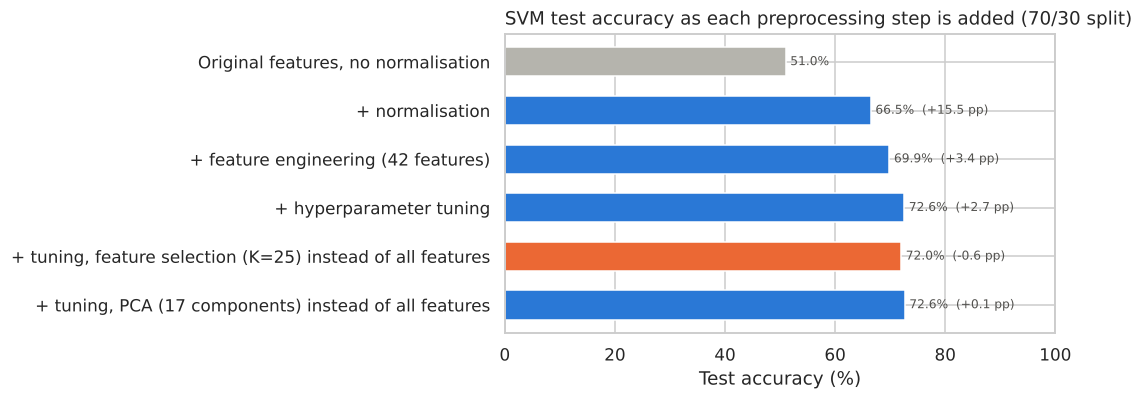

In [28]:
steps = []
m = Pipeline([("svc", SVC())]).fit(model_df[ORIGINAL_FEATURES].iloc[train_idx], y_model.iloc[train_idx])
steps.append(("Original features, no normalisation", m.score(model_df[ORIGINAL_FEATURES].iloc[test_idx], y_model.iloc[test_idx])))
m = Pipeline([("pre", make_preprocessor(ORIGINAL_FEATURES, scaling_plan_all)), ("svc", SVC())])
m.fit(model_df[ORIGINAL_FEATURES].iloc[train_idx], y_model.iloc[train_idx])
steps.append(("+ normalisation", m.score(model_df[ORIGINAL_FEATURES].iloc[test_idx], y_model.iloc[test_idx])))
steps.append(("+ feature engineering (42 features)", svm_base_result["split_accuracy"]))
steps.append(("+ hyperparameter tuning", svm_tuned_result["split_accuracy"]))
steps.append((f"+ tuning, feature selection (K={BEST_K}) instead of all features", svm_kbest_result["split_accuracy"]))
steps.append((f"+ tuning, PCA ({BEST_N} components) instead of all features", svm_pca_result["split_accuracy"]))
ablation = pd.DataFrame(steps, columns=["step", "split_accuracy"]).set_index("step")
reference = [None, 0, 1, 2, 3, 3]          # each step is compared with the step it builds on
ablation["change_pp"] = [np.nan] + [100 * (ablation["split_accuracy"].iloc[i] - ablation["split_accuracy"].iloc[ref])
                                    for i, ref in enumerate(reference) if ref is not None]
display(ablation.round(4))

fig, ax = plt.subplots(figsize=(10, 3.8))
vals = ablation["split_accuracy"] * 100
colors = [COLOR_GREY] + [COLOR_MAIN if c >= 0 else COLOR_SECOND for c in ablation["change_pp"].iloc[1:]]
bars = ax.barh(vals.index[::-1], vals.values[::-1], color=colors[::-1], height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" + ("" if np.isnan(c) else f"  ({c:+.1f} pp)")
                           for v, c in zip(vals.values[::-1], ablation["change_pp"].values[::-1])],
             padding=3, fontsize=8, color=COLOR_TEXT)
ax.set_xlim(0, 100)
ax.set_title("SVM test accuracy as each preprocessing step is added (70/30 split)", loc="left")
ax.set_xlabel("Test accuracy (%)")
fig.tight_layout()
save_fig(fig, "pa2_task10_step_impact")
plt.show()

### 10.2 Robustness check: chronological split
The Studio 3 protocol uses shuffled data. Because the data is a time series (neighbouring readings are almost identical, autocorrelation 0.75; PA1 Task 6), shuffling lets the model see readings from the same hours as the test set. As an additional check, the best models are trained on the **first 70% of the period** and tested on the **last 30%**.

In [29]:
cut = int(len(df) * (1 - TEST_SIZE))
chrono_train, chrono_test = np.arange(cut), np.arange(cut, len(df))
print(f"Chronological split: train {df['date'].iloc[0]:%d %b} – {df['date'].iloc[cut - 1]:%d %b}, "
      f"test {df['date'].iloc[cut]:%d %b} – {df['date'].iloc[-1]:%d %b}")
y_time = df[CLASS_COL].cat.codes.astype(int)

chrono_rows = []
for label, model, cols, random_acc in [
        (f"Decision Tree – {best_dt_name}", make_dt(*DT_MODELS[best_dt_name]), DT_MODELS[best_dt_name][0],
         dt_results.loc[best_dt_name, "test_accuracy"]),
        (f"SVM with hyperparameter tuning {BEST_PARAMS}", svm_pipeline(**BEST_PARAMS), SVM_FEATURES,
         svm_tuned_result["split_accuracy"])]:
    model.fit(df[cols].iloc[chrono_train], y_time.iloc[chrono_train])
    chrono_rows.append({"model": label, "shuffled 70/30 accuracy": random_acc,
                        "chronological 70/30 accuracy": model.score(df[cols].iloc[chrono_test], y_time.iloc[chrono_test])})
chrono = pd.DataFrame(chrono_rows).set_index("model")
chrono["difference (pp)"] = 100 * (chrono["chronological 70/30 accuracy"] - chrono["shuffled 70/30 accuracy"])
display(chrono.round(4))
print("Class shares in the chronological test period (%):",
      (df[CLASS_COL].iloc[chrono_test].value_counts(normalize=True).reindex(CLASS_LABELS) * 100).round(1).to_dict())

Chronological split: train 11 Jan – 16 Apr, test 16 Apr – 27 May


,shuffled 70/30 accuracy,chronological 70/30 accuracy,difference (pp)
model,,,
Decision Tree – Model 3: Original + engineered (normalised),0.6815,0.4303,-25.1140
"SVM with hyperparameter tuning {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}",0.7256,0.4560,-26.9549


Class shares in the chronological test period (%): {'Low': 29.3, 'Medium': 39.4, 'High': 31.3}


### 10.3 Reflection questions (Studio 3) and recommendations
**Summary.** All three improved SVMs reach 72.0–73.4%. The **tuned SVM on all 42 features (C = 10, gamma = 0.1)** has the highest CV accuracy (**73.43% ± 0.88**; 72.56% on the split). The PCA version is equivalent (72.64% split, 73.23% CV): the differences between these two are far below the CV standard deviation. Both are about 4 pp above the best Decision Tree and almost double the majority-class baseline (37.8%).

**1. Which preprocessing technique had the biggest impact on model performance?** **Normalisation**, by far, for the SVM. The step-by-step comparison in Task 10.1 shows the SVM on the 24 original features rising from **51.02% without normalisation to 66.48% with it (+15.45 pp)**. Without scaling, large-valued features such as pressure (≈755 mm Hg) dominate every distance. Feature engineering adds **+3.38 pp** (69.85%) and tuning **+2.70 pp** (72.56%). Feature selection (−0.56 pp) and PCA (+0.08 pp) do not improve accuracy; their value is a smaller model (40% and 60% fewer inputs). The answer depends on the model: for the Decision Trees, normalisation made no difference (Task 5, Q2 and Q5) and the choice of features mattered most.

**2. Did hyperparameter tuning significantly improve your SVM model? By how much?** Yes: **+2.70 pp on the split (69.85% → 72.56%) and +3.35 pp in CV (70.08% → 73.43%)**, which removes about 11% of the CV errors (error rate 29.9% → 26.6%). The gain appears in both evaluation methods and is several times larger than the fold-to-fold standard deviation (0.4–0.9 pp), so it is a real improvement. It comes mainly from gamma (0.1 instead of the default ≈ 0.028).

**3. Decision Tree (Activity 1) vs SVM (Activity 7): which performed better for this dataset?** The **SVM**, in every comparison. The best tree (Model 3) reaches 68.15% on the split and 69.27% in CV; the tuned SVM reaches 72.56% and 73.43%, i.e. **+4.41 pp and +4.16 pp**. Even the default SVM beats the best tree. The tree memorises the training data (100% training accuracy, about 2,600 leaves), while the RBF-SVM fits a smooth boundary, controlled by C and gamma, that generalises better.

**4. Was there a trade-off between model performance and interpretability?** Yes.
- **The Decision Tree is interpretable in principle.** Every prediction is a chain of thresholds in physical units, and the feature importances show which inputs drive it (`hour_sin`, `hour_cos`, `RH_kitchen_excess`). In practice, a tree with about 2,600 leaves is too large to read, and it is the least accurate model.
- **The tuned SVM is about 4 pp more accurate but is a black box.** Its decision is a weighted sum of RBF similarities to **8,750 support vectors** (63% of the training rows) in a 42-dimensional scaled space, and it gives no feature importances (permutation importance would be needed).
- **Within the SVMs,** SelectKBest keeps 25 named features and needs fewer sensors, for −0.6 to −0.8 pp. PCA keeps the accuracy but replaces the features with abstract components, and it still needs all the sensors.
- **Choice:** the tuned SVM if accuracy is the priority; the SelectKBest SVM, or a pruned tree, if the model has to be explained to a building manager.

**Robustness to time (important limitation).** With a chronological split (train 11 Jan – 16 Apr, test 16 Apr – 27 May), accuracy falls to **43.03% for the Decision Tree and 45.60% for the tuned SVM** (−25.11 pp and −26.95 pp). The shuffled split of Studio 3 is optimistic for two reasons:
- Neighbouring 10-minute readings are almost identical (autocorrelation 0.75), so the test set contains near-copies of training points.
- The house changes from winter to spring (non-stationarity, PA1 §4.4). The class mix also shifts: Medium makes up 39.4% of the test period compared with 30.6% overall.

The SVM keeps the advantage over the tree, but the chronological result is the more realistic estimate for predicting future consumption.

**Recommendations.**
- Use the tuned SVM with the engineered time and activity features as the current best model, but report its performance with **time-based validation** (for example, `TimeSeriesSplit`).
- Add **lagged consumption** and more months of data (including summer), so that the model sees every season, and retrain it regularly to handle drift.
- Select features with **mutual information** rather than the F-test, to keep non-linear features such as `dRH1_30min`.
- Try tree ensembles (Random Forest, gradient boosting). They reduce the overfitting of single trees and still give feature importances.